#### **Project Name - Real Estate Investment Advisor: Predicting Property Profitability & Future Value**

#### **Project Type - Supervised Learning (Binary Classification + Regression)**

#### **Domain - Real Estate / Investment / Financial Analytics**

#### **Contribution - Individual**

#### **Name - Mohit Singh Rajput**

#### **GitHub Link - https://github.com/13msrajput/Real-Estate-Investment-Advisor**

#### **Streamlit App Link - add your live app link here**

#### **Problem Statement**

Buying property is one of the largest financial decisions most people make, yet investors often rely on gut feeling, broker opinions or a simple price-per-square-foot comparison. This project builds a machine learning application that assists potential investors by answering two questions for any property in India:

1. **Classification** - Is this property a **Good Investment**?

2. **Regression** - What will its **estimated price be after 5 years**?

The system cleans and analyses a dataset of **250,000 property listings across 20 states and 42 cities**, engineers investment-relevant features, trains and compares multiple models, tracks every experiment with **MLflow**, and serves the final models through an interactive **Streamlit** application with investment recommendations, price forecasts, visual insights, model confidence scores and feature importance.

#### **Project Summary**

##### **-> **What Was Built****

- **Data Pipeline** - Loaded and validated **250,000 property records (23 columns)**. The file had no missing values and no duplicates, but a quality audit found **116,304 rows (46.5%) where the floor number exceeded the building height**; these were capped and flagged. Price per sq ft was recomputed in rupees because the source column is rounded to two decimals of lakhs.

- **Exploratory Data Analysis** - Answered all **20 EDA questions** from the project brief with 20 charts, each followed by data-driven insights. The central finding is that prices in this dataset are almost independent of size, BHK, city and property type, which shapes every modelling decision that follows.

- **Feature Engineering** - Created Price per Sq Ft (INR), Price vs City Median, Price per Sq Ft vs City Median, School Density Score, Infrastructure Score (0-100), Amenity Count and flags, Floor Ratio, Size per BHK and a City Demand Index.

- **Targets** - **Good_Investment** is a transparent four-factor rule score (value, affordability, infrastructure, growth; at least 3 of 4 points, 31.5% positives). **Future_Price_5Y = Current Price x (1 + r)^5**, where r is a feature-based annual growth rate between 3% and 12%.

- **Classification Models** - Logistic Regression, Random Forest and XGBoost compared; **XGBoost** selected with **F1 = 0.9951**, accuracy 0.9969 and ROC-AUC 0.9999 on 50,000 held-out properties.

- **Regression Models** - Linear Regression, Random Forest and XGBoost compared; **XGBoost** selected with **RMSE = 7.89 lakhs**, MAE 5.54 lakhs and R2 0.9984, against RMSE 29.94 for a naive fixed 8% growth benchmark.

- **Honesty Checks** - Two of the four label factors depend on price, so the headline accuracy is largely rule recovery. A leakage ablation that removes every price column leaves only the infrastructure and growth factors to learn: accuracy falls to 71.9% (ROC-AUC 0.828) against a majority baseline of 68.5%.

- **Experiment Tracking** - Every model run is logged to **MLflow** (parameters, metrics, figures, fitted pipelines) and the champion models are registered in the MLflow Model Registry with a `champion` alias.

- **Deployment** - A four-tab Streamlit app: Investment Advisor (form, verdict, confidence gauge, 5-year forecast with a 90% range), Property Explorer (filters by state, city, BHK, price, size), Market Insights (heatmaps and trend charts) and Model Insights.

#### **Business Objectives**

- Empower real estate investors with intelligent tools to assess long-term returns.

- Support buyers in choosing high-return properties in developing areas.

- Help real estate companies automate investment analysis for listings.

- Improve customer trust in real estate platforms with data-backed predictions.

- Track every experiment with MLflow so the best models are versioned, reproducible and ready to deploy.

#### **Let's Begin !**

#### **1. Know Your Data**

##### **Import Libraries**

In [ ]:
# Standard library helpers
import sys
import json
import warnings
from pathlib import Path

# Core data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning utilities
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    KFold,
)
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

# Make the project's src package importable when the notebook runs from the project root
sys.path.insert(0, str(Path.cwd()))

# Project modules (single source of truth shared with the Streamlit app)
from src import config as cfg
from src import modeling as mdl
from src.data_loader import load_raw_data, clean_data, detect_outliers_iqr
from src.features import build_training_frame, engineer_features

# Hide non-critical warnings to keep the notebook output readable
warnings.filterwarnings("ignore")

# Consistent plot style across the notebook
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# Show all columns when printing wide tables
pd.set_option("display.max_columns", None)

##### **Dataset Loading**

In [2]:
# Load the raw dataset (the loader validates the schema and raises clear errors if the file is missing)
df = load_raw_data()

2026-10-26 16:22:17,386 | INFO | src.data_loader | Loaded 250,000 rows and 23 columns from C:\Labmentix Internship Projects\Real-Estate-Investment-Advisor\data\raw\india_housing_prices.csv


##### **Dataset First View**

In [3]:
# Preview the first five rows
df.head()

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


##### **Dataset Rows and Columns Count**

In [ ]:
# Get row and column counts
rows, columns = df.shape

# Print them with thousands separators
print(f"Number of Rows : {rows:,}")
print(f"Number of Columns : {columns}")

Number of Rows    : 250,000
Number of Columns : 23


##### **Dataset Information**

In [5]:
# Show column names, non-null counts and dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors               

##### **Duplicate Values**

In [ ]:
# Count fully duplicated rows (the unique ID column is ignored)
duplicate_count = df.drop(columns="ID").duplicated().sum()

# Print the result
print(f"Total Duplicate Rows : {duplicate_count}")

Total Duplicate Rows : 0


##### **Missing Values / Null Values**

In [ ]:
# Count missing values per column
missing_values = df.isnull().sum()

# Print only the columns that have gaps (an empty result means the data is complete)
print(
    missing_values[missing_values > 0]
    if missing_values.sum() > 0
    else "No missing values in any column."
)

No missing values in any column.


In [ ]:
# Compute the missing value percentage per column
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

# Show the top five columns
missing_pct.head()

ID               0.0
State            0.0
City             0.0
Locality         0.0
Property_Type    0.0
dtype: float64

##### **Key Insights**

- The dataset has **250,000 rows and 23 columns** covering residential properties in **20 states and 42 cities**.

- There are **no missing values and no duplicate listings**, so no imputation or row removal is needed for completeness - but completeness is not the same as correctness, as the next sections show.

- **46.5% of rows have a `Floor_No` greater than `Total_Floors`**, which is physically impossible (for example a flat on floor 22 of a 1-storey building). This is the biggest data-quality problem in the file and is corrected during wrangling.

- `Locality` has 500 generic labels (`Locality_1` ... `Locality_500`), and every locality name appears in all 42 cities, so it is **not a real geographic identifier** and is excluded from model features.

- `Amenities` is a comma-separated text field and needs to be parsed into numeric features.

#### **2. Understanding Variables**

##### **Dataset Columns**

In [9]:
# List all column names
df.columns

Index(['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK',
       'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built',
       'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property',
       'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility',
       'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type',
       'Availability_Status'],
      dtype='str')

##### **Describe Dataset**

In [10]:
# Statistical summary of the numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.500000,72168.927986,1.0,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,2.999396,1.415521,1.0,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.0,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.586854,141.349921,10.0,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.130597,0.130747,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.520012,9.808575,1990.0,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.966800,8.948047,0.0,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.503004,8.671618,1.0,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.479988,9.808575,2.0,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.499860,2.878639,1.0,3.00,5.00,8.00,10.00


In [ ]:
# Statistical summary of the categorical columns
(
    df.describe(include="object").T
    if df.select_dtypes("object").shape[1]
    else df.describe(exclude="number").T
)

,count,unique,top,freq
State,250000,20,Odisha,12681
City,250000,42,Coimbatore,6461
Locality,250000,500,Locality_296,567
Property_Type,250000,3,Villa,83744
Furnished_Status,250000,3,Unfurnished,83408
Public_Transport_Accessibility,250000,3,High,83705
Parking_Space,250000,2,No,125456
Security,250000,2,Yes,125233
Amenities,250000,325,Pool,10218
Facing,250000,4,West,62757


##### **Variables Description**

| Column | Type | Description |
|--------|------|-------------|
| `ID` | int | Unique identifier for each property record |
| `State` | object | State where the property is located |
| `City` | object | City of the property |
| `Locality` | object | Neighbourhood label (generic `Locality_n` names) |
| `Property_Type` | object | Apartment, Independent House or Villa |
| `BHK` | int | Number of bedrooms, hall and kitchen (1-5) |
| `Size_in_SqFt` | int | Area of the property in square feet |
| `Price_in_Lakhs` | float | Property price in lakhs (1 lakh = 100,000 INR) |
| `Price_per_SqFt` | float | Price divided by area, in **lakhs** per sq ft (rounded to 2 decimals) |
| `Year_Built` | int | Year the property was constructed |
| `Furnished_Status` | object | Furnished, Semi-furnished or Unfurnished |
| `Floor_No` | int | Floor on which the property sits |
| `Total_Floors` | int | Total floors in the building |
| `Age_of_Property` | int | Age in years (2025 minus `Year_Built`) |
| `Nearby_Schools` | int | Number of nearby schools (0-10) |
| `Nearby_Hospitals` | int | Number of nearby hospitals (0-10) |
| `Public_Transport_Accessibility` | object | Low, Medium or High |
| `Parking_Space` | object | Whether parking is available (Yes / No) |
| `Security` | object | Whether security is provided (Yes / No) |
| `Amenities` | object | Comma-separated list (Gym, Pool, Clubhouse, Garden, Playground) |
| `Facing` | object | Direction the property faces |
| `Owner_Type` | object | Owner, Builder or Broker |
| `Availability_Status` | object | Ready_to_Move or Under_Construction |

##### **Key Insights**

- `Price_in_Lakhs` ranges from **10.00 to 500.00 lakhs** with a mean of 254.6 and a median of 253.9 - the mean and median almost coincide, which is typical of a symmetric (near-uniform) distribution rather than the right-skewed shape of real housing prices.

- `Size_in_SqFt` spans **500 to 5,000 sq ft**, again with mean (2,750) close to median (2,747).

- The correlation between `Size_in_SqFt` and `Price_in_Lakhs` is only **-0.003** - in real markets bigger homes cost more, so this is an early sign that the data is synthetic.

- `Price_per_SqFt` is stored in **lakhs** and rounded to two decimals (values like 0.05, 0.10), which destroys precision. It is recomputed in rupees during wrangling.

- `Age_of_Property` equals 2025 minus `Year_Built` for **all 250,000 rows**, so the reference year is 2025.

##### **Checking Unique Values for Each Variable**

In [12]:
# Print the number of unique values per column
for col in df.columns:

    # Count distinct values
    print(f"  {col:32s} : {df[col].nunique():,}")

  ID                               : 250,000
  State                            : 20
  City                             : 42
  Locality                         : 500
  Property_Type                    : 3
  BHK                              : 5
  Size_in_SqFt                     : 4,501
  Price_in_Lakhs                   : 48,700
  Price_per_SqFt                   : 100
  Year_Built                       : 34
  Furnished_Status                 : 3
  Floor_No                         : 31
  Total_Floors                     : 30
  Age_of_Property                  : 34
  Nearby_Schools                   : 10
  Nearby_Hospitals                 : 10
  Public_Transport_Accessibility   : 3
  Parking_Space                    : 2
  Security                         : 2
  Amenities                        : 325
  Facing                           : 4
  Owner_Type                       : 3
  Availability_Status              : 2


#### **3. Data Wrangling**

##### **Data Preprocessing and Cleaning**

In [13]:
# clean_data() works on a copy so the raw dataframe stays untouched
# Steps: strip text, drop duplicates, drop/impute missing values, enforce business rules,
# recompute age, cap impossible floors (with a flag), rebuild price per sq ft in rupees
df1, cleaning_report = clean_data(df)

# Print the audit trail of what each step changed
for step, value in cleaning_report.items():

    # One line per step
    print(f"{step:35s} : {value:,}")

2026-10-26 16:22:18,689 | INFO | src.data_loader | Cleaning complete: 250,000 -> 250,000 rows
rows_raw                            : 250,000
duplicates_removed                  : 0
rows_dropped_missing_key_fields     : 0
cells_imputed                       : 0
rows_dropped_invalid_values         : 0
age_values_corrected                : 0
floor_values_corrected              : 116,304
rows_clean                          : 250,000


In [ ]:
# Preview the cleaned data with the new columns
df1[
    [
        "City",
        "Price_in_Lakhs",
        "Size_in_SqFt",
        "Price_per_SqFt",
        "Price_per_SqFt_INR",
        "Floor_No",
        "Total_Floors",
        "Floor_Data_Corrected",
    ]
].head()

,City,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Price_per_SqFt_INR,Floor_No,Total_Floors,Floor_Data_Corrected
0,Chennai,489.76,4740,0.10,10332.489451,1,1,1
1,Pune,195.52,2364,0.08,8270.727580,20,20,1
2,Ludhiana,183.79,3642,0.05,5046.403075,19,27,0
3,Jodhpur,300.29,2741,0.11,10955.490697,21,26,0
4,Jaipur,182.90,4823,0.04,3792.245490,2,2,1


##### **Data Wrangling Summary**

| Step | Action | Rows / Cells Affected | Reason |
|------|--------|-----------------------|--------|
| Copy | `df.copy()` | - | Preserve the original data |
| Text cleanup | Strip whitespace, empty string to null | all text columns | Avoid hidden category duplicates |
| Duplicates | `drop_duplicates` (ignoring `ID`) | 0 removed | Avoid double counting listings |
| Missing key fields | `dropna` on price, size, BHK, year | 0 removed | Target-defining fields cannot be guessed |
| Imputation | Median (numeric) / mode (categorical) | 0 cells | Keep rows with minor gaps |
| Business rules | Price, size, BHK, floors > 0; year built <= 2025 | 0 removed | Remove impossible records |
| Property age | Recompute as 2025 - `Year_Built` | 0 corrected | Guarantee consistency |
| Impossible floors | Cap `Floor_No` at `Total_Floors`, add `Floor_Data_Corrected` flag | **116,304 corrected** | Floor cannot exceed building height |
| Price per sq ft | `Price_per_SqFt_INR` = lakhs x 100,000 / size | all rows | Source column loses precision from rounding |

##### **Key Insights**

- The cleaned dataset keeps **250,000 rows** - nothing had to be thrown away for being missing or duplicated, which is unusual for real-world data and consistent with a generated dataset.

- The one substantial fix is the floor correction: **116,304 rows (46.5%)** had a floor above the building height. They are kept (capped to the top floor) rather than deleted, because removing almost half the data would be far more damaging than a capped floor value. The `Floor_Data_Corrected` flag keeps the correction transparent.

- `Price_per_SqFt_INR` ranges from **Rs 202 to Rs 99,182** per sq ft with a median of Rs 9,245. This enormous spread is an artefact of price and size being drawn independently: a 500 sq ft flat can be priced like a 5,000 sq ft one.

#### **4. Data Visualization, Storytelling and Experimenting with Charts**

The 20 charts below answer the 20 EDA questions in the project brief, grouped as in the brief: price and size, location, feature relationships and investment / amenities / ownership. Every chart is followed by insights computed directly from the data.

#### **Price and Size Analysis (Questions 1-5)**

##### **Chart - 1 : Distribution of Property Prices**

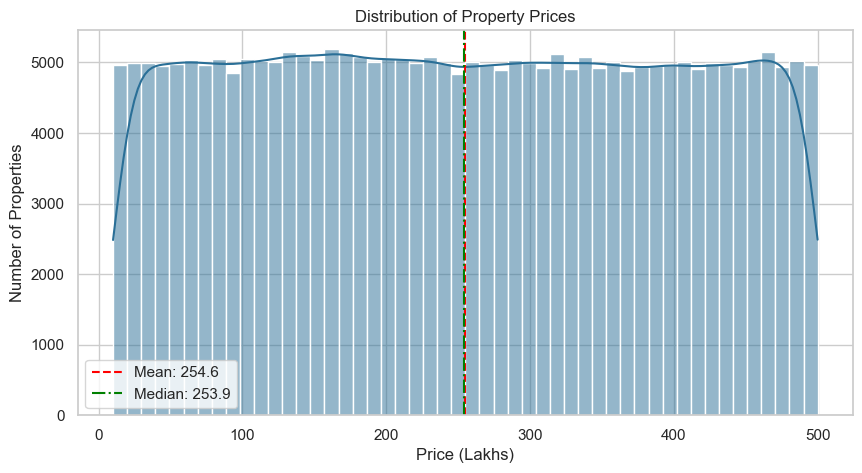

In [ ]:
# Histogram of property prices (in lakhs) with mean and median markers
plt.figure(figsize=(10, 5))

# Draw the histogram with a kernel density curve
sns.histplot(df1["Price_in_Lakhs"], bins=50, kde=True, color="#2a6f97")

# Mark the mean and the median
plt.axvline(
    df1["Price_in_Lakhs"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {df1['Price_in_Lakhs'].mean():.1f}",
)
plt.axvline(
    df1["Price_in_Lakhs"].median(),
    color="green",
    linestyle="-.",
    label=f"Median: {df1['Price_in_Lakhs'].median():.1f}",
)

# Labels and title
plt.title("Distribution of Property Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Properties")
plt.legend()
plt.show()

##### **Key Insights**

- Prices run from **10.0 to 500.0 lakhs** (mean 254.6, median 253.9, standard deviation 141.3).

- The distribution is **essentially flat (uniform)**: splitting the price range into five equal bands puts between 19.9% and 20.3% of properties in each band, and skewness is just +0.008.

- Real housing markets are right-skewed with a long tail of luxury properties. A uniform shape means prices were drawn from a fixed range, so the model cannot rely on a typical 'expensive tail' pattern.

##### **Chart - 2 : Distribution of Property Sizes**

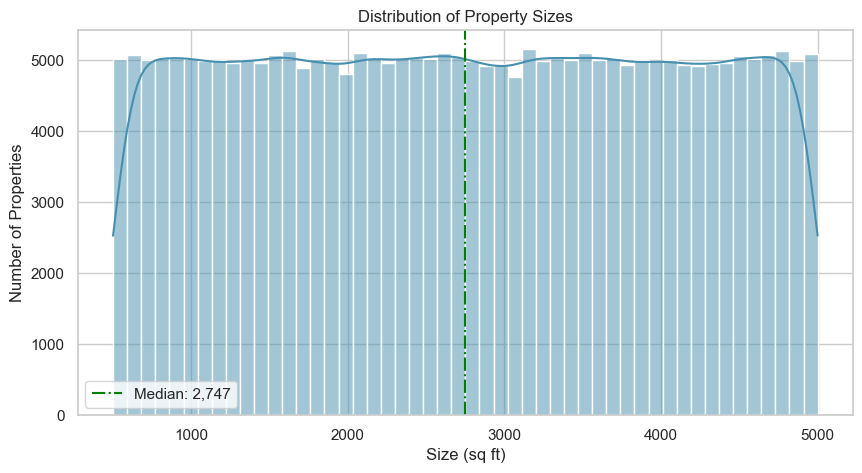

In [ ]:
# Histogram of property sizes in square feet
plt.figure(figsize=(10, 5))

# Draw the histogram with a density curve
sns.histplot(df1["Size_in_SqFt"], bins=50, kde=True, color="#468faf")

# Mark the median
plt.axvline(
    df1["Size_in_SqFt"].median(),
    color="green",
    linestyle="-.",
    label=f"Median: {df1['Size_in_SqFt'].median():,.0f}",
)

# Labels and title
plt.title("Distribution of Property Sizes")
plt.xlabel("Size (sq ft)")
plt.ylabel("Number of Properties")
plt.legend()
plt.show()

##### **Key Insights**

- Sizes span **500 to 5,000 sq ft** with a median of 2,747.

- Like price, size is **uniformly distributed** - every one of five equal size bands holds 20.0% to 20.0% of the properties.

- A 5,000 sq ft property is as common as a 500 sq ft one, which is unrealistic for a market where compact apartments dominate. Together with the flat price histogram this explains the extreme price-per-sq-ft values seen later.

##### **Chart - 3 : Price per Sq Ft by Property Type**

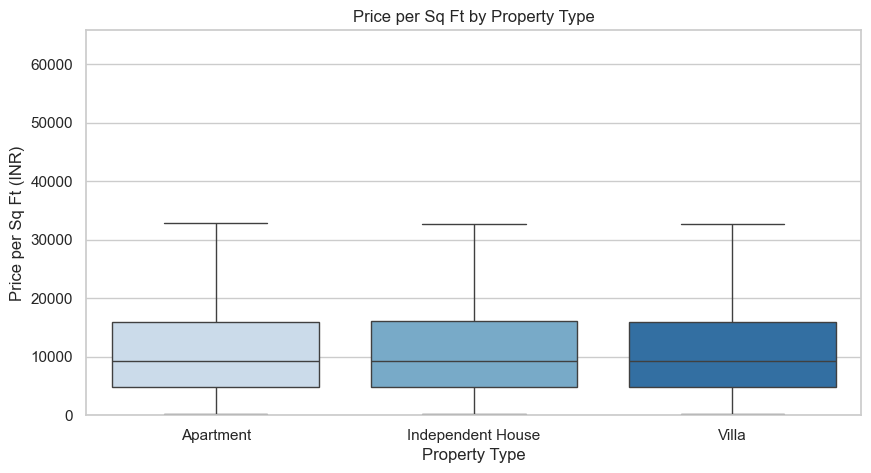

In [ ]:
# Box plot of rupee price per sq ft by property type (clipped at the 99th percentile so the axis stays readable)
plt.figure(figsize=(10, 5))

# Upper display limit
upper = df1["Price_per_SqFt_INR"].quantile(0.99)

# Draw the box plot
sns.boxplot(
    data=df1,
    x="Property_Type",
    y="Price_per_SqFt_INR",
    showfliers=False,
    palette="Blues",
)

# Labels and title
plt.title("Price per Sq Ft by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price per Sq Ft (INR)")
plt.ylim(0, upper)
plt.show()

##### **Key Insights**

- Median price per sq ft by type: **Apartment** Rs 9,245, **Independent House** Rs 9,305, **Villa** Rs 9,190.

- The three types are almost identical - highest **Independent House** (Rs 9,305) vs lowest **Villa** (Rs 9,190), a gap of only **1.2%** of the average.

- In real markets villas and independent houses carry a land premium and apartments are priced differently per sq ft. Here property type does not move price at all, so it will not be an important model feature.

##### **Chart - 4 : Property Size vs Price**

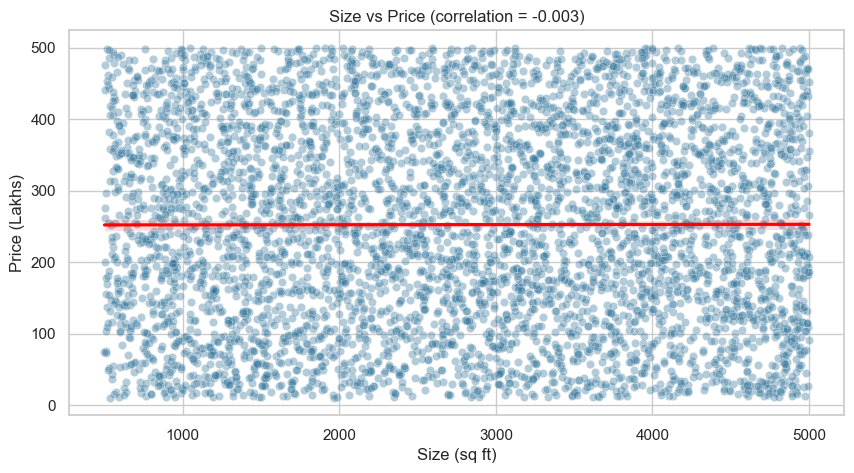

In [ ]:
# Scatter plot of size against price on a 5,000 row sample
sample = df1.sample(5000, random_state=42)

plt.figure(figsize=(10, 5))

# Draw the scatter with some transparency
sns.scatterplot(
    data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.35, color="#2a6f97"
)

# Add a regression line to show the trend
sns.regplot(
    data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", scatter=False, color="red"
)

# Labels and title
plt.title(
    f"Size vs Price (correlation = {df1['Size_in_SqFt'].corr(df1['Price_in_Lakhs']):+.3f})"
)
plt.xlabel("Size (sq ft)")
plt.ylabel("Price (Lakhs)")
plt.show()

##### **Key Insights**

- The correlation between size and price is **-0.003** - effectively zero. The scatter is a uniform rectangle with a flat regression line.

- In any real city a larger home costs more, so the expected answer to 'Is there a relationship between size and price?' would be a strong positive one. In this dataset there is **no relationship**.

- Because price per sq ft is price divided by size, it ends up strongly negatively correlated with size (-0.615): small properties look extremely expensive per sq ft and large ones look cheap. This is a mathematical side effect, not a market signal, and is handled by using **ratios to city medians** and winsorisation in the models.

##### **Chart - 5 : Outliers in Price per Sq Ft and Property Size**

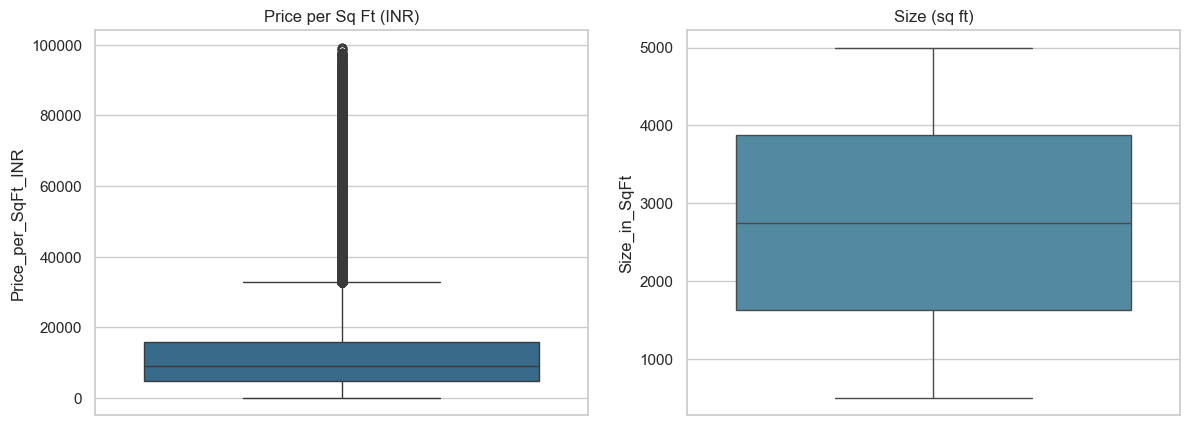

In [ ]:
# Box plots to inspect outliers for price per sq ft and size
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price per sq ft (rupees)
sns.boxplot(y=df1["Price_per_SqFt_INR"], ax=axes[0], color="#2a6f97")
axes[0].set_title("Price per Sq Ft (INR)")

# Size in sq ft
sns.boxplot(y=df1["Size_in_SqFt"], ax=axes[1], color="#468faf")
axes[1].set_title("Size (sq ft)")

plt.show()

In [20]:
# Count outliers with the 1.5 x IQR rule
detect_outliers_iqr(df1, ["Price_per_SqFt_INR", "Size_in_SqFt", "Price_in_Lakhs"])

,Column,Lower_Fence,Upper_Fence,Outliers,Outlier_Pct
0,Price_per_SqFt_INR,-11973.983,32764.212,19723,7.89
1,Size_in_SqFt,-1753.500,7250.500,0,0.00
2,Price_in_Lakhs,-233.945,743.375,0,0.00


##### **Key Insights**

- **Size and price have no IQR outliers** (0 and 0) because both are bounded uniform variables.

- **Price per sq ft has 19,723 outliers (7.9%)** above the upper fence of Rs 32,764, reaching Rs 99,182. These are tiny flats with large price tags, created by the independent price and size draws.

- Treatment: the outliers are **winsorised at the 1st and 99th percentiles** only in the model feature `Price_per_SqFt_Capped`. The raw value is kept for the label rules, and tree models are robust to the remaining skew.

#### **Location-based Analysis (Questions 6-10)**

##### **Chart - 6 : Average Price per Sq Ft by State**

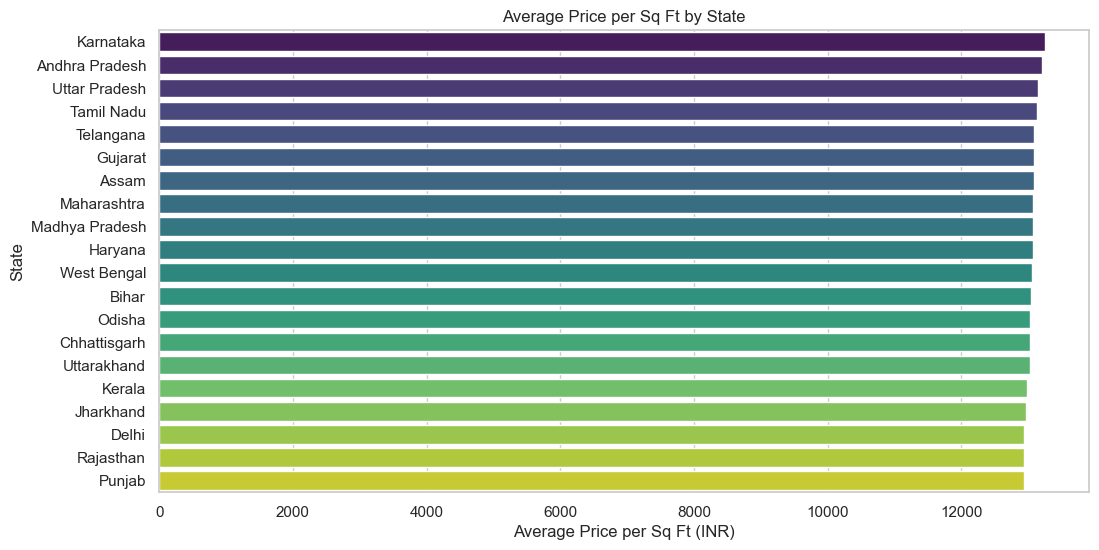

In [ ]:
# Average rupee price per sq ft for every state, sorted from highest to lowest
state_pps = (
    df1.groupby("State")["Price_per_SqFt_INR"].mean().sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

# Horizontal bar chart
sns.barplot(x=state_pps.values, y=state_pps.index, palette="viridis")

# Labels and title
plt.title("Average Price per Sq Ft by State")
plt.xlabel("Average Price per Sq Ft (INR)")
plt.ylabel("State")
plt.show()

##### **Key Insights**

- Across 20 states: highest **Karnataka** (Rs 13,252) vs lowest **Punjab** (Rs 12,931), a gap of only **2.5%** of the average.

- The ranking exists, but the differences are within sampling noise. In real India, Maharashtra, Delhi and Karnataka are far more expensive per sq ft than Bihar or Chhattisgarh; **that real-world geography is absent here**.

- Location therefore cannot drive price in the models. It still matters for the label because properties are compared with their own city's median.

##### **Chart - 7 : Average Property Price by City**

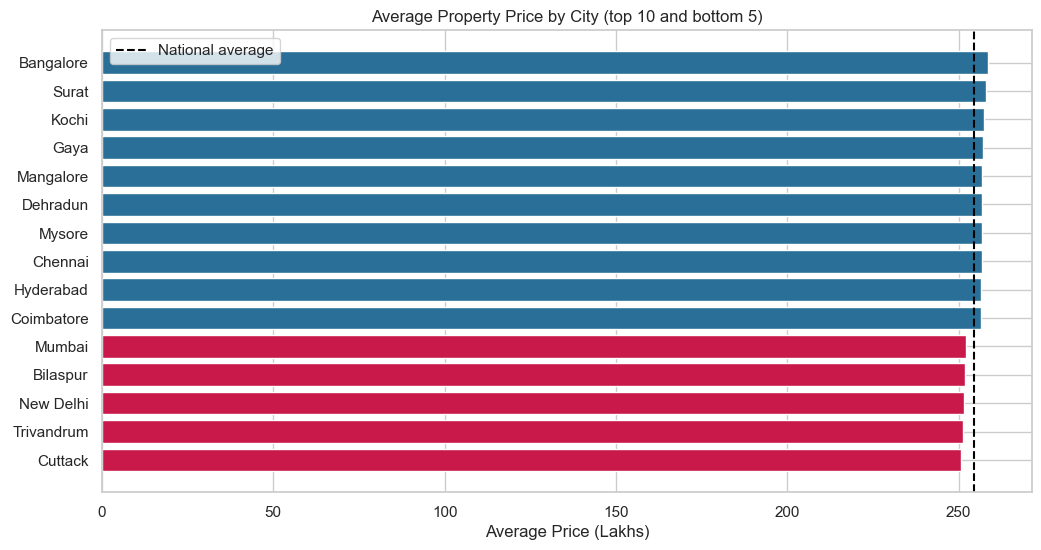

In [ ]:
# Average price per city: show the 10 highest and 5 lowest
city_price = df1.groupby("City")["Price_in_Lakhs"].mean().sort_values(ascending=False)
shown = pd.concat([city_price.head(10), city_price.tail(5)])

plt.figure(figsize=(12, 6))

# Colour the top group and bottom group differently
colors = ["#2a6f97"] * 10 + ["#c9184a"] * 5
plt.barh(shown.index[::-1], shown.values[::-1], color=colors[::-1])

# Reference line at the national average
plt.axvline(
    df1["Price_in_Lakhs"].mean(),
    color="black",
    linestyle="--",
    label="National average",
)

# Labels and title
plt.title("Average Property Price by City (top 10 and bottom 5)")
plt.xlabel("Average Price (Lakhs)")
plt.legend()
plt.show()

##### **Key Insights**

- Across 42 cities the average price ranges from **250.8 to 258.5 lakhs** - highest **Bangalore** (258.5 lakhs) vs lowest **Cuttack** (250.8 lakhs), a gap of only **3.0%** of the average.

- **Bangalore** tops the list and **Cuttack** is last, but a spread of 7.7 lakhs on a ~255 lakh average is negligible.

- Mumbai, Delhi and Bangalore are not meaningfully more expensive than small cities in this file. City is therefore a weak predictor of price, and the investment label depends on how a property compares with its own city rather than across cities.

##### **Chart - 8 : Median Age of Properties by Locality**

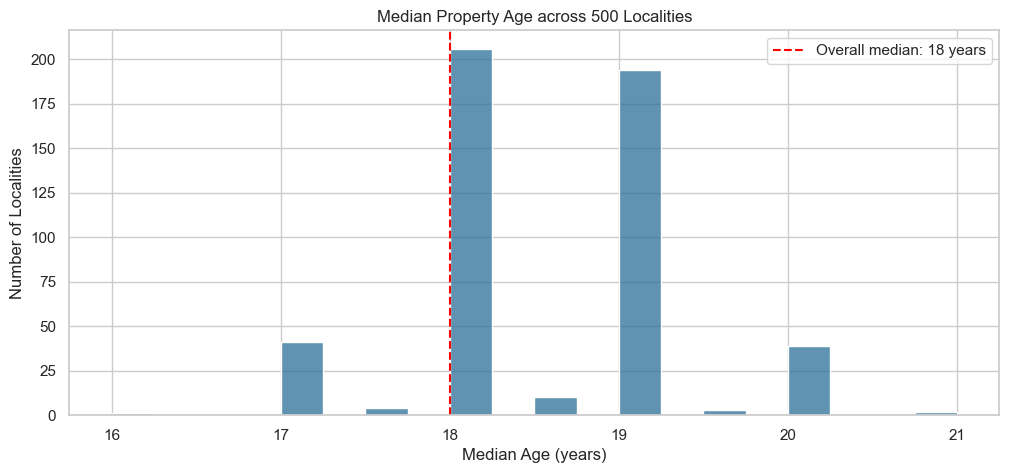

In [ ]:
# Median property age for every locality (500 localities)
locality_age = df1.groupby("Locality")["Age_of_Property"].median().sort_values()

plt.figure(figsize=(12, 5))

# Histogram of the 500 locality medians
sns.histplot(locality_age, bins=20, color="#2a6f97")

# Mark the overall median age
plt.axvline(
    df1["Age_of_Property"].median(),
    color="red",
    linestyle="--",
    label=f"Overall median: {df1['Age_of_Property'].median():.0f} years",
)

# Labels and title
plt.title("Median Property Age across 500 Localities")
plt.xlabel("Median Age (years)")
plt.ylabel("Number of Localities")
plt.legend()
plt.show()

In [24]:
# Show the 5 newest and 5 oldest localities
print("Newest localities:\n", locality_age.head(5), "\n")
print("Oldest localities:\n", locality_age.tail(5))

Newest localities:
 Locality
Locality_443    16.0
Locality_92     17.0
Locality_60     17.0
Locality_10     17.0
Locality_13     17.0
Name: Age_of_Property, dtype: float64 

Oldest localities:
 Locality
Locality_499    20.0
Locality_99     20.0
Locality_127    20.0
Locality_403    21.0
Locality_72     21.0
Name: Age_of_Property, dtype: float64


##### **Key Insights**

- Locality medians range from **16 to 21 years**, centred on the overall median of 18 years.

- The newest locality is **Locality_443** (16 years) and the oldest is **Locality_72** (21 years).

- Property age is spread evenly from 2 to 35 years inside every locality, so there are no genuinely 'new development' or 'old town' areas. Because locality labels repeat in all cities, they are dropped from the model features.

##### **Chart - 9 : BHK Distribution across Cities**

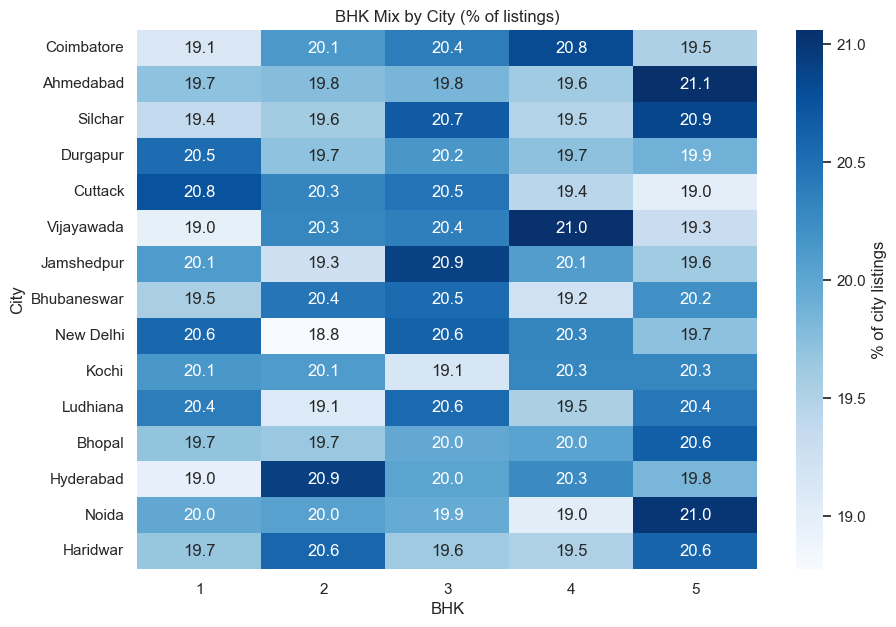

In [ ]:
# Share of each BHK type within each city (15 largest cities by listing count)
top_cities = df1["City"].value_counts().head(15).index

# Row-normalised crosstab: each city sums to 100%
bhk_share = (
    pd.crosstab(df1["City"], df1["BHK"], normalize="index").loc[top_cities] * 100
)

plt.figure(figsize=(10, 7))

# Heatmap of percentages
sns.heatmap(
    bhk_share,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar_kws={"label": "% of city listings"},
)

# Labels and title
plt.title("BHK Mix by City (% of listings)")
plt.xlabel("BHK")
plt.ylabel("City")
plt.show()

##### **Key Insights**

- Every BHK type (1 to 5) makes up roughly one fifth of listings in every city; across all cities the share of any BHK type lies between **18.6% and 22.0%**.

- A real market would be dominated by 2 and 3 BHK homes, with 5 BHK a rarity. Here BHK is uniformly random and independent of city.

- BHK is also unrelated to size: average size per BHK is 2,745-2,753 sq ft across all five groups, so a '1 BHK' can be larger than a '5 BHK'. This is why the engineered `Size_per_BHK` feature is kept but not expected to carry strong signal.

##### **Chart - 10 : Price Trends for the Top 5 Most Expensive Localities**

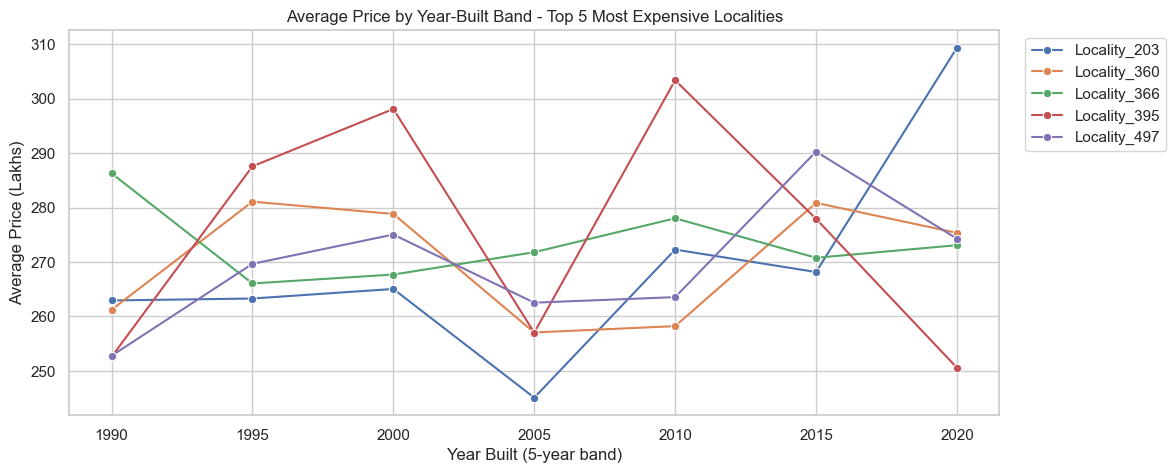

In [ ]:
# Identify the 5 localities with the highest average price
top5 = (
    df1.groupby("Locality")["Price_in_Lakhs"]
    .mean()
    .sort_values(ascending=False)
    .head(5)
    .index
)

# The dataset has no sale dates, so the trend is shown by construction-year band (5-year bins)
subset = df1[df1["Locality"].isin(top5)].copy()
subset["Year_Band"] = (subset["Year_Built"] // 5) * 5

# Average price for every locality and year band
trend = subset.groupby(["Year_Band", "Locality"])["Price_in_Lakhs"].mean().reset_index()

plt.figure(figsize=(12, 5))

# One line per locality
sns.lineplot(data=trend, x="Year_Band", y="Price_in_Lakhs", hue="Locality", marker="o")

# Labels and title
plt.title("Average Price by Year-Built Band - Top 5 Most Expensive Localities")
plt.xlabel("Year Built (5-year band)")
plt.ylabel("Average Price (Lakhs)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

##### **Key Insights**

- The five most expensive localities are **Locality_395** (275.4 lakhs), **Locality_366** (273.4 lakhs), **Locality_497** (270.0 lakhs), **Locality_360** (269.8 lakhs), **Locality_203** (269.0 lakhs).

- Even the top five average only +14.5 to +20.8 lakhs from the all-locality mean of 254.6, so 'most expensive' is a thin label.

- The lines zig-zag in different directions: the correlation between year band and average price is -0.07, -0.22, +0.61, +0.15, +0.62 for the five localities. With only about seven year bands per line these swings are noise, not trends.

- The dataset also has no transaction dates, so a genuine **time trend cannot be measured** - this is the reason the 5-year price target is built from documented growth assumptions rather than learned from history.

#### **Feature Relationship and Correlation (Questions 11-15)**

##### **Chart - 11 : Correlation Between Numeric Features**

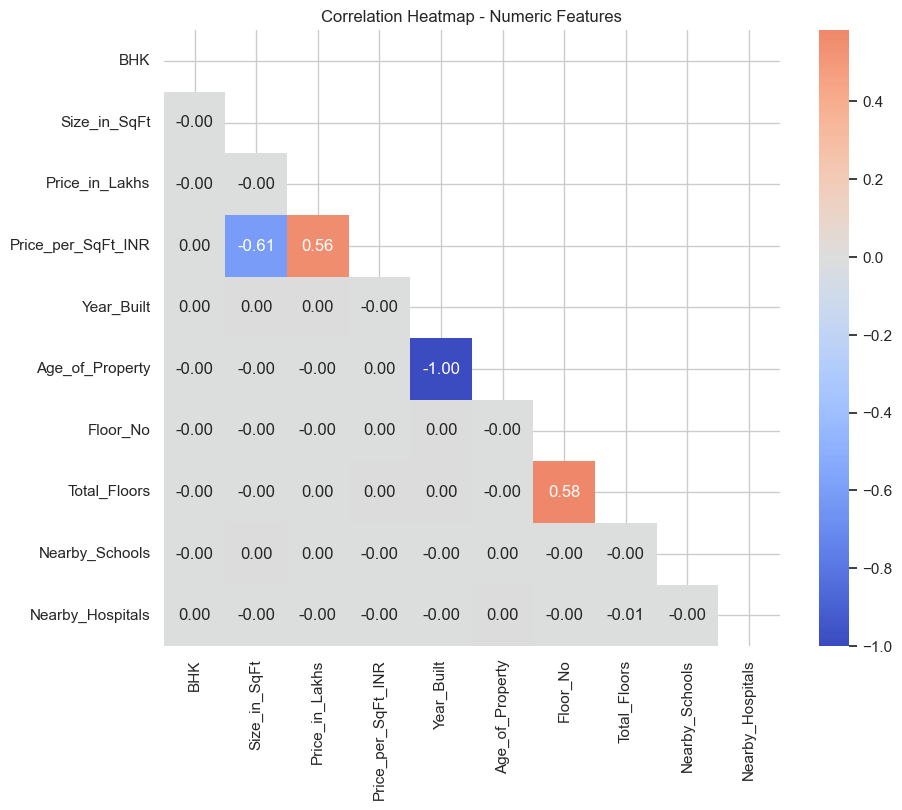

In [ ]:
# Correlation matrix of the numeric columns (ID is excluded because it carries no information)
numeric_cols = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt_INR",
    "Year_Built",
    "Age_of_Property",
    "Floor_No",
    "Total_Floors",
    "Nearby_Schools",
    "Nearby_Hospitals",
]
corr = df1[numeric_cols].corr()

plt.figure(figsize=(10, 8))

# Mask the upper triangle so each pair appears once
mask = np.triu(np.ones_like(corr, dtype=bool))

# Heatmap with annotations
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True
)

# Title
plt.title("Correlation Heatmap - Numeric Features")
plt.show()

##### **Key Insights**

- The strongest correlation is **Year_Built vs Age_of_Property (-1.00)**, which is expected because age is derived from the year built (the two are the same information).

- The next strongest pairs involve price per sq ft: **Size_in_SqFt vs Price_per_SqFt_INR (-0.61)** and **Floor_No vs Total_Floors (+0.58)**. These follow from the formula (price / size).

- Excluding derived pairs, every remaining correlation is within ±0.56: price, size, BHK, floors, schools and hospitals are **statistically independent** of one another.

- Because the original columns carry no cross-feature signal, predictive power must come from engineered ratios (price vs city median, infrastructure score) rather than raw columns.

##### **Chart - 12 : Nearby Schools vs Price per Sq Ft**

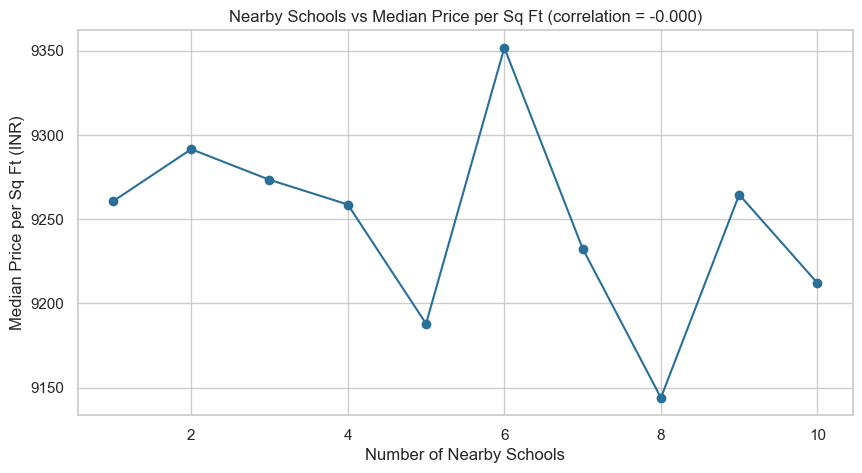

In [ ]:
# Median price per sq ft for every nearby-school count (0 to 10)
schools_pps = df1.groupby("Nearby_Schools")["Price_per_SqFt_INR"].median()

plt.figure(figsize=(10, 5))

# Line chart with markers
plt.plot(schools_pps.index, schools_pps.values, marker="o", color="#2a6f97")

# Labels and title
plt.title(
    f"Nearby Schools vs Median Price per Sq Ft (correlation = {df1['Nearby_Schools'].corr(df1['Price_per_SqFt_INR']):+.3f})"
)
plt.xlabel("Number of Nearby Schools")
plt.ylabel("Median Price per Sq Ft (INR)")
plt.show()

##### **Key Insights**

- Correlation between nearby schools and price per sq ft is **-0.000** (essentially zero).

- Median price per sq ft by school count moves between Rs 9,144 and Rs 9,352 with no upward direction.

- Good school access normally lifts property values, but it does not in this data. Schools still contribute to the **Infrastructure Score** and the **School Density Score** used in the investment label, because a buyer values them regardless of how the historical prices look.

##### **Chart - 13 : Nearby Hospitals vs Price per Sq Ft**

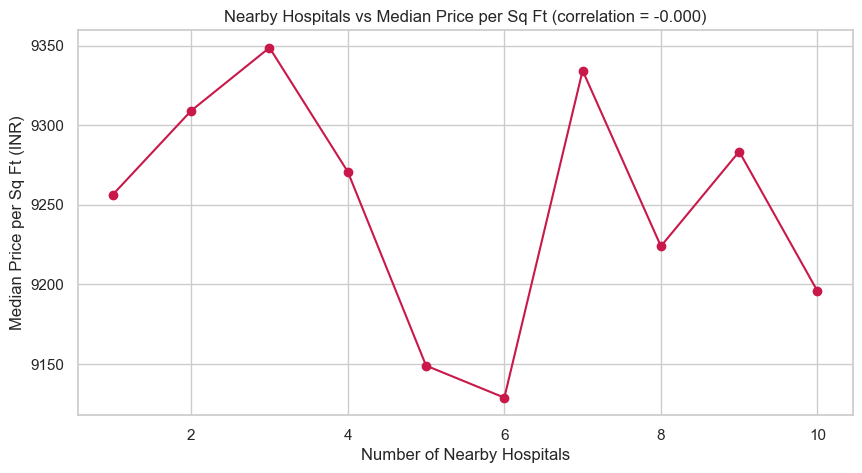

In [ ]:
# Median price per sq ft for every nearby-hospital count (0 to 10)
hosp_pps = df1.groupby("Nearby_Hospitals")["Price_per_SqFt_INR"].median()

plt.figure(figsize=(10, 5))

# Line chart with markers
plt.plot(hosp_pps.index, hosp_pps.values, marker="o", color="#c9184a")

# Labels and title
plt.title(
    f"Nearby Hospitals vs Median Price per Sq Ft (correlation = {df1['Nearby_Hospitals'].corr(df1['Price_per_SqFt_INR']):+.3f})"
)
plt.xlabel("Number of Nearby Hospitals")
plt.ylabel("Median Price per Sq Ft (INR)")
plt.show()

##### **Key Insights**

- Correlation between nearby hospitals and price per sq ft is **-0.000**.

- Median price per sq ft ranges only from Rs 9,129 to Rs 9,349 across hospital counts and shows no trend.

- As with schools, hospital access does not explain price here, but it is retained in the Infrastructure Score because healthcare access is a standard investment criterion.

##### **Chart - 14 : Price by Furnished Status**

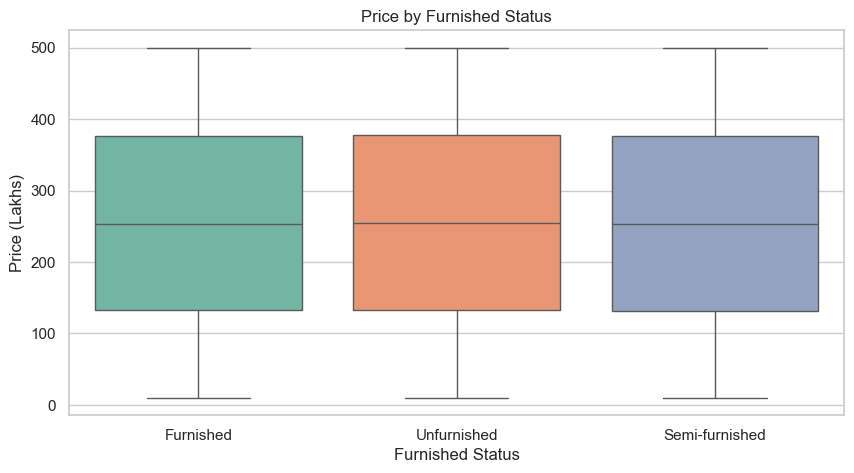

In [ ]:
# Box plot of price by furnishing level
plt.figure(figsize=(10, 5))

# Draw the box plot
sns.boxplot(data=df1, x="Furnished_Status", y="Price_in_Lakhs", palette="Set2")

# Labels and title
plt.title("Price by Furnished Status")
plt.xlabel("Furnished Status")
plt.ylabel("Price (Lakhs)")
plt.show()

##### **Key Insights**

- Average price by furnishing: **Furnished** 254.4 lakhs, **Semi-furnished** 254.3 lakhs, **Unfurnished** 255.0 lakhs.

- highest **Unfurnished** (255.0 lakhs) vs lowest **Semi-furnished** (254.3 lakhs), a gap of only **0.3%** of the average - furnished flats are not priced above unfurnished ones.

- The three boxes have the same median, quartiles and whiskers, confirming that furnishing level has no effect on price in this dataset.

##### **Chart - 15 : Price per Sq Ft by Facing Direction**

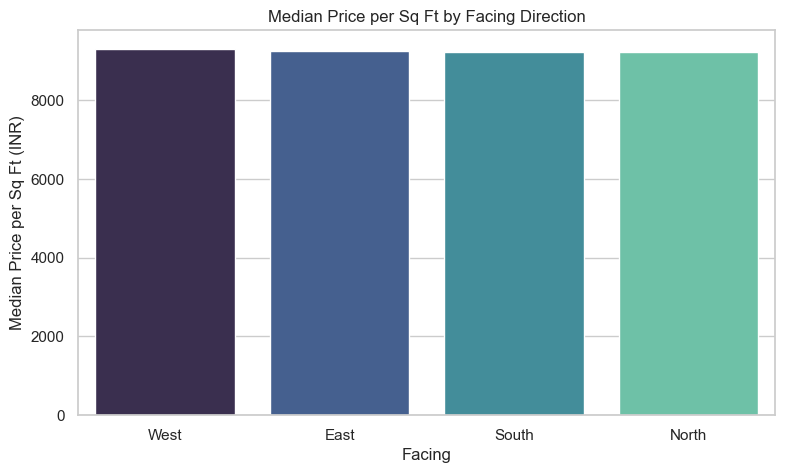

In [ ]:
# Median price per sq ft by facing direction
facing_pps = (
    df1.groupby("Facing")["Price_per_SqFt_INR"].median().sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

# Bar chart
sns.barplot(x=facing_pps.index, y=facing_pps.values, palette="mako")

# Labels and title
plt.title("Median Price per Sq Ft by Facing Direction")
plt.xlabel("Facing")
plt.ylabel("Median Price per Sq Ft (INR)")
plt.show()

##### **Key Insights**

- Median price per sq ft by facing: **West** Rs 9,308, **East** Rs 9,234, **South** Rs 9,225, **North** Rs 9,219.

- highest **West** (Rs 9,308) vs lowest **North** (Rs 9,219), a gap of only **1.0%** of the average.

- In Indian real estate (Vastu preferences) east- and north-facing homes often command a premium; no such premium appears here.

#### **Investment, Amenities and Ownership Analysis (Questions 16-20)**

##### **Chart - 16 : Number of Properties by Owner Type**

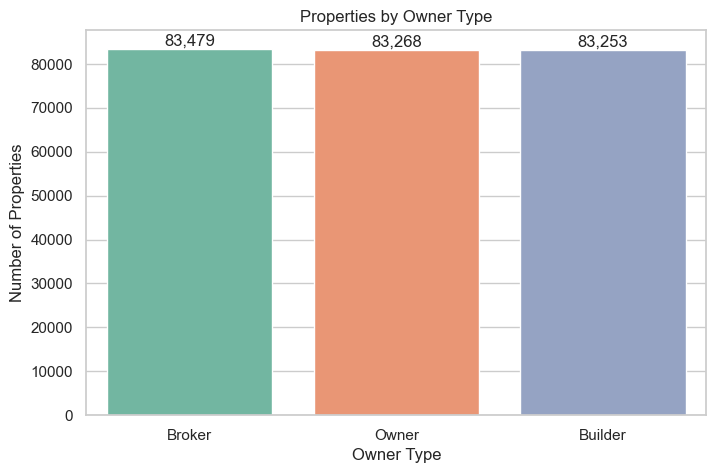

In [ ]:
# Count of properties by owner type
owner_counts = df1["Owner_Type"].value_counts()

plt.figure(figsize=(8, 5))

# Bar chart
ax = sns.barplot(x=owner_counts.index, y=owner_counts.values, palette="Set2")

# Write the count above every bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

# Labels and title
plt.title("Properties by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Number of Properties")
plt.show()

##### **Key Insights**

- Listings by owner type: **Broker** 83,479 (33.4%), **Owner** 83,268 (33.3%), **Builder** 83,253 (33.3%).

- The three owner types are almost perfectly balanced - each holds roughly one third of the market.

- Owner type is kept as a categorical model feature, but price by owner type is also flat, so no broker or builder premium is expected.

##### **Chart - 17 : Number of Properties by Availability Status**

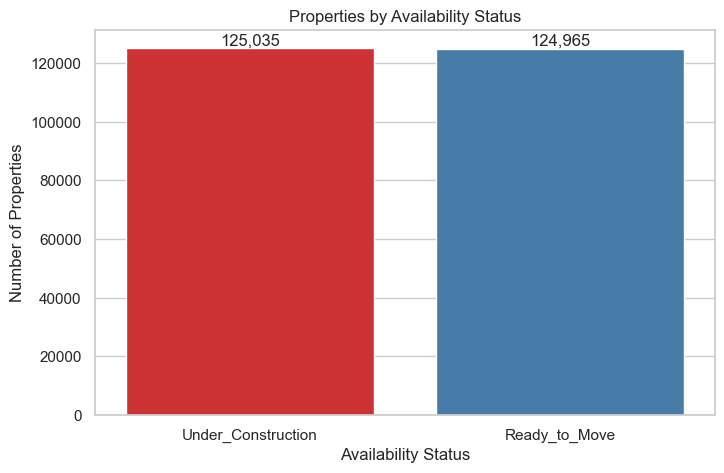

In [ ]:
# Count of properties by availability status
avail_counts = df1["Availability_Status"].value_counts()

plt.figure(figsize=(8, 5))

# Bar chart
ax = sns.barplot(x=avail_counts.index, y=avail_counts.values, palette="Set1")

# Write the count above every bar
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

# Labels and title
plt.title("Properties by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Properties")
plt.show()

##### **Key Insights**

- Listings by status: **Under_Construction** 125,035 (50.0%), **Ready_to_Move** 124,965 (50.0%).

- The market is split roughly 50/50 between ready-to-move and under-construction properties.

- Under-construction properties with an age above zero (average age 18 years) are another sign of synthetic data. In the growth assumptions, under-construction properties receive a small appreciation premium (+0.8% a year) because value is realised on completion.

##### **Chart - 18 : Effect of Parking Space on Price**

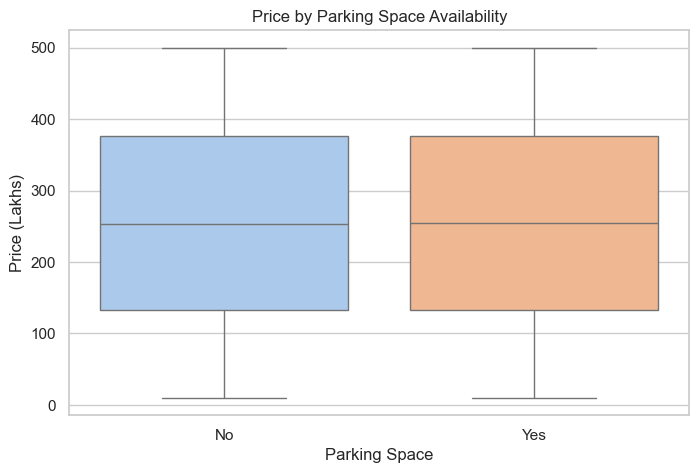

In [ ]:
# Box plot of price by parking availability
plt.figure(figsize=(8, 5))

# Draw the box plot
sns.boxplot(data=df1, x="Parking_Space", y="Price_in_Lakhs", palette="pastel")

# Labels and title
plt.title("Price by Parking Space Availability")
plt.xlabel("Parking Space")
plt.ylabel("Price (Lakhs)")
plt.show()

##### **Key Insights**

- Average price with parking: **254.7 lakhs**; without: **254.4 lakhs** - a difference of +0.32 lakhs (+0.12%).

- Parking does **not** affect price in this dataset, even though in dense Indian cities a parking slot can add several lakhs.

- It is still counted (10% weight) in the Infrastructure Score because the buyer's convenience and resale appeal exist independently of the historical price pattern.

##### **Chart - 19 : Effect of Amenities on Price per Sq Ft**

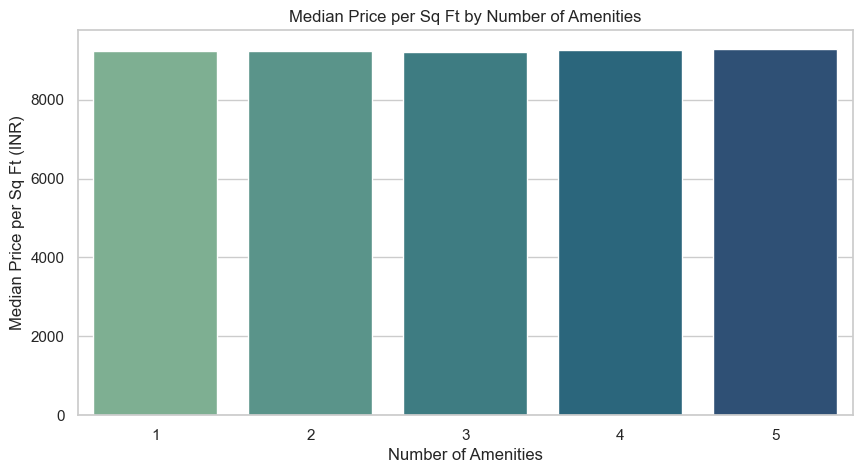

In [ ]:
# Create a numeric amenity count from the comma-separated Amenities text
df1["Amenity_Count"] = (
    df1["Amenities"]
    .fillna("")
    .apply(lambda text: len([a for a in text.split(",") if a.strip()]))
)

# Median price per sq ft by number of amenities
amen_pps = df1.groupby("Amenity_Count")["Price_per_SqFt_INR"].median()

plt.figure(figsize=(10, 5))

# Bar chart
sns.barplot(x=amen_pps.index, y=amen_pps.values, palette="crest")

# Labels and title
plt.title("Median Price per Sq Ft by Number of Amenities")
plt.xlabel("Number of Amenities")
plt.ylabel("Median Price per Sq Ft (INR)")
plt.show()

##### **Key Insights**

- Properties have between 1 and 5 amenities; median price per sq ft by count ranges Rs 9,207 to Rs 9,294 with no upward pattern.

- Median price per sq ft with versus without each amenity: Gym +0.5%, Pool +0.1%, Clubhouse -0.1%, Garden +0.1%, Playground +0.3% - all within normal noise.

- Amenities do not command a price premium here. They are kept as `Amenity_Count` plus one flag per amenity and feed the Infrastructure Score.

##### **Chart - 20 : Public Transport Accessibility vs Price per Sq Ft and Investment Potential**

2026-10-26 16:22:27,178 | INFO | src.features | Reference tables fitted on 250,000 rows (infra threshold 57.5, median growth 6.94%)
2026-10-26 16:22:27,954 | INFO | src.features | Good_Investment share: 31.5% | mean growth 6.95%


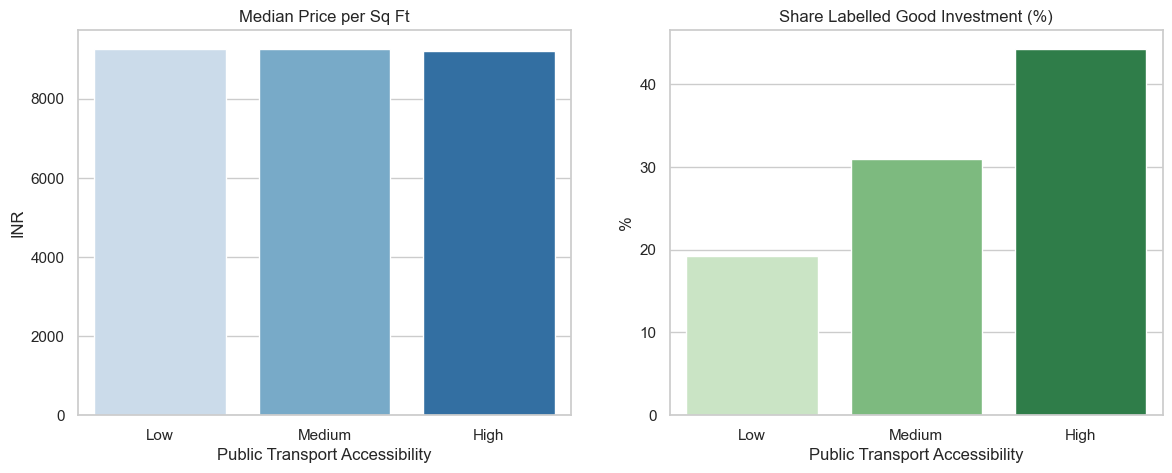

In [ ]:
# Preview of the investment label: the formal target creation happens in Section 5
data_preview, _ = build_training_frame(df1)

# Order the accessibility levels from Low to High
order = ["Low", "Medium", "High"]

# Median price per sq ft and share of good investments for every level
transport_pps = (
    data_preview.groupby("Public_Transport_Accessibility")["Price_per_SqFt_INR"]
    .median()
    .reindex(order)
)
transport_good = (
    data_preview.groupby("Public_Transport_Accessibility")["Good_Investment"]
    .mean()
    .reindex(order)
    * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: price per sq ft
sns.barplot(x=transport_pps.index, y=transport_pps.values, ax=axes[0], palette="Blues")
axes[0].set_title("Median Price per Sq Ft")
axes[0].set_ylabel("INR")

# Right: investment potential
sns.barplot(
    x=transport_good.index, y=transport_good.values, ax=axes[1], palette="Greens"
)
axes[1].set_title("Share Labelled Good Investment (%)")
axes[1].set_ylabel("%")

# Common x label
for ax in axes:
    ax.set_xlabel("Public Transport Accessibility")

plt.show()

##### **Key Insights**

- Median price per sq ft by accessibility: **Low** Rs 9,265, **Medium** Rs 9,269, **High** Rs 9,205 - **no relationship with price**.

- Share labelled Good Investment: **Low** 19.2%, **Medium** 30.9%, **High** 44.3%.

- The Good Investment share rises from 19.2% to 44.3% with accessibility. This is **by construction**: transport carries 25% of the Infrastructure Score and feeds the growth-rate formula that earn points in the label. It reflects the investment philosophy encoded in the rules (connectivity supports appreciation), not an observed market effect.

#### **5. Feature Engineering and Data Preprocessing**

##### **1. Handling Outliers**

In [ ]:
# Winsorisation bounds: 1st and 99th percentile of the rupee price per sq ft
pps_low, pps_high = df1["Price_per_SqFt_INR"].quantile([0.01, 0.99])

# Compare the distribution before and after capping
comparison_outliers = pd.DataFrame(
    {
        "Before capping": df1["Price_per_SqFt_INR"].describe(),
        "After capping": df1["Price_per_SqFt_INR"].clip(pps_low, pps_high).describe(),
    }
)

# Show the effect (rounded for readability)
comparison_outliers.round(0)

,Before capping,After capping
count,250000.0,250000.0
mean,13058.0,12959.0
std,13072.0,12594.0
min,202.0,498.0
25%,4803.0,4803.0
50%,9245.0,9245.0
75%,15987.0,15987.0
max,99182.0,65823.0


##### **What outlier treatment was applied and why?**

- **Detection** - the 1.5 x IQR rule (Chart 5) flagged outliers only in price per sq ft; price and size are bounded and have none.

- **Treatment** - **winsorisation (capping)** at the 1st and 99th percentiles, stored as `Price_per_SqFt_Capped`. Capping keeps all 250,000 rows, whereas removing the extreme rows would delete exactly the 'tiny flat, big price' properties an investor most needs the model to judge.

- **Raw value preserved** - the uncapped price per sq ft is used for the investment-label rules and the city-median ratio, so the capped column only feeds scale-sensitive models such as Logistic Regression.

- **Tree models** (Random Forest, XGBoost) are insensitive to monotonic scaling and extreme values, so they are unaffected by the cap.

##### **2. Feature Creation**

In [ ]:
# Build every engineered feature plus both targets in one call
# data = engineered dataset, ref = market benchmark tables (city medians, demand index, thresholds)
data, ref = build_training_frame(df1)

# Preview the new columns
data[
    [
        "City",
        "Price_in_Lakhs",
        "Price_per_SqFt_INR",
        "PPS_vs_City_Median",
        "Price_vs_City_Median",
        "School_Density_Score",
        "Amenity_Count",
        "Infra_Score",
        "Floor_Ratio",
        "City_Demand_Index",
        "Expected_Growth_Rate",
    ]
].head()

2026-10-26 16:22:28,735 | INFO | src.features | Reference tables fitted on 250,000 rows (infra threshold 57.5, median growth 6.94%)
2026-10-26 16:22:29,520 | INFO | src.features | Good_Investment share: 31.5% | mean growth 6.95%


,City,Price_in_Lakhs,Price_per_SqFt_INR,PPS_vs_City_Median,Price_vs_City_Median,School_Density_Score,Amenity_Count,Infra_Score,Floor_Ratio,City_Demand_Index,Expected_Growth_Rate
0,Chennai,489.76,10332.489451,1.107619,1.949061,1.843658,5,67.5,1.000000,0.8293,0.070879
1,Pune,195.52,8270.727580,0.867067,0.740087,1.436524,5,37.5,1.000000,0.9756,0.086268
2,Ludhiana,183.79,5046.403075,0.551249,0.739508,1.649258,4,60.5,0.703704,0.1463,0.052489
3,Jodhpur,300.29,10955.490697,1.181934,1.193925,0.905797,5,80.0,0.807692,0.6098,0.067294
4,Jaipur,182.90,3792.245490,0.417123,0.706150,0.723982,5,47.5,1.000000,0.0976,0.050928


##### **Engineered Feature Description**

| Feature | Formula / Logic | Why it matters |
|---------|-----------------|----------------|
| `Price_per_SqFt_INR` | `Price_in_Lakhs x 100,000 / Size_in_SqFt` | Standard value metric (brief) |
| `PPS_vs_City_Median` | Property price per sq ft / median of its city | Below 1 means cheaper than the local market |
| `Price_vs_City_Median` | Price / median price of the same city and property type | Affordability versus comparable homes |
| `School_Density_Score` | Nearby schools / average schools in the city | Locality-relative education access (brief) |
| `Transport_Score` | Low = 1, Medium = 2, High = 3 | Ordinal connectivity |
| `Amenity_Count`, `Has_<Amenity>` | Parsed from the `Amenities` text | Lifestyle features in numeric form |
| `Infra_Score` | Weighted 0-100: schools 25%, hospitals 25%, transport 25%, parking 10%, amenities 10%, security 5% | Single infrastructure measure (brief) |
| `Floor_Ratio` | `Floor_No / Total_Floors` | Position in the building (0 = ground, 1 = top) |
| `Size_per_BHK` | `Size_in_SqFt / BHK` | Spaciousness proxy |
| `City_Demand_Index` | Rank of the city's median price per sq ft, scaled 0-1 | Market demand level |
| `Is_Under_Construction` | 1 if `Availability_Status` is Under_Construction | Delivery risk and completion upside |

##### **3. Target Creation - Good Investment (Classification)**

The brief asks for a binary **Good Investment** label "based on domain rules". A property earns **one point for each of four factors** and is labelled good when it earns **at least 3 of 4**:

| Factor | Rule | Brief reference |
|--------|------|-----------------|
| Value | `PPS_vs_City_Median <= 1` (price per sq ft at or below the city median) | Price per Sq Ft |
| Affordability | `Price_vs_City_Median <= 1` (price at or below the median for the same city and type) | Price vs Median |
| Infrastructure | `Infra_Score >= 57.5` (top 40% of all properties) | Multi-factor score |
| Growth | `Expected_Growth_Rate >= 6.94%` (median expected appreciation) | Appreciation rate > threshold |

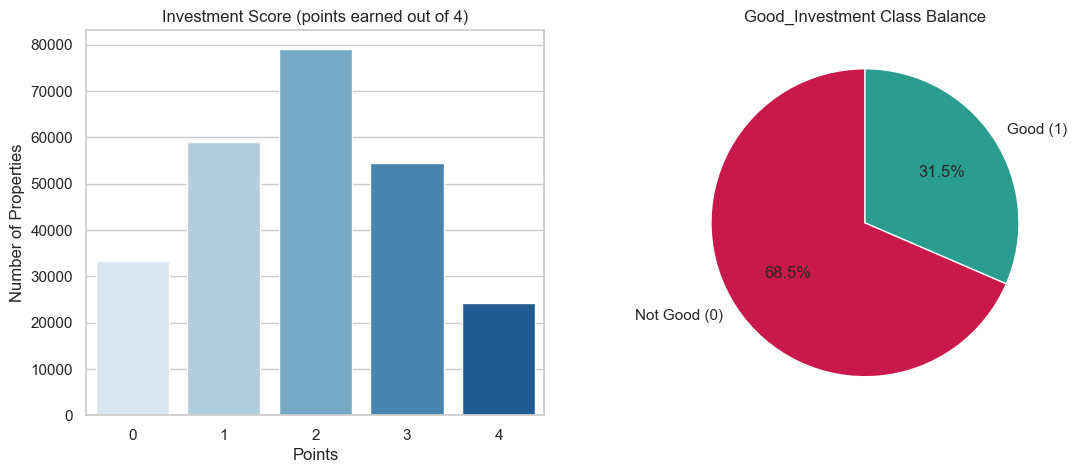

In [ ]:
# Distribution of the 0-4 investment score and the resulting binary label
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: how many properties earned 0, 1, 2, 3 or 4 points
score_counts = data["Investment_Score"].value_counts().sort_index()
sns.barplot(x=score_counts.index, y=score_counts.values, ax=axes[0], palette="Blues")
axes[0].set_title("Investment Score (points earned out of 4)")
axes[0].set_xlabel("Points")
axes[0].set_ylabel("Number of Properties")

# Right: class balance of the final label
label_counts = data["Good_Investment"].value_counts().sort_index()
axes[1].pie(
    label_counts.values,
    labels=["Not Good (0)", "Good (1)"],
    autopct="%1.1f%%",
    colors=["#c9184a", "#2a9d8f"],
    startangle=90,
)
axes[1].set_title("Good_Investment Class Balance")

plt.show()

##### **Target Creation - Future Price after 5 Years (Regression)**

The dataset is a **single snapshot** - there is no price history - so true appreciation cannot be learned from it. The brief offers three options (fixed rate, location / type based, feature based). This project uses the **feature-based option**:

`Future_Price_5Y = Price_in_Lakhs x (1 + r) ^ 5`, where the annual growth rate `r` is

`r = 0.045 + 0.030 x City_Demand_Index + 0.020 x Infra_Score/100 + 0.008 x Under_Construction - 0.0005 x max(Age - 10, 0) + noise`

with reproducible Gaussian market noise (standard deviation 0.004) and growth clipped to 3%-12%. A fixed 8% rate is used as a **benchmark** that the model must beat. All assumptions live in `src/config.py` so they can be changed in one place.

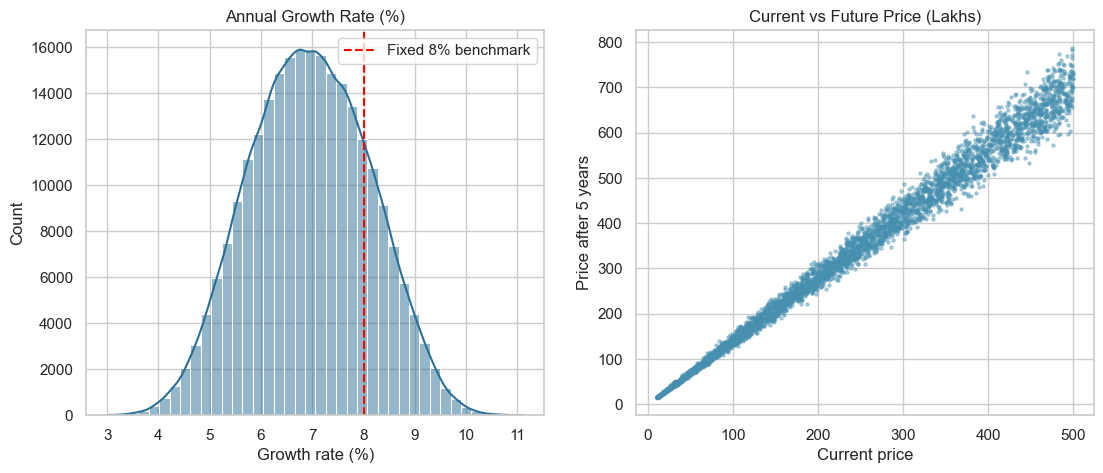

In [ ]:
# Distribution of the annual growth rate and of the 5-year price uplift
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: realised annual growth rate
sns.histplot(data["Growth_Rate"] * 100, bins=40, kde=True, ax=axes[0], color="#2a6f97")
axes[0].axvline(8, color="red", linestyle="--", label="Fixed 8% benchmark")
axes[0].set_title("Annual Growth Rate (%)")
axes[0].set_xlabel("Growth rate (%)")
axes[0].legend()

# Right: current versus future price on a sample
sample = data.sample(4000, random_state=42)
axes[1].scatter(
    sample["Price_in_Lakhs"], sample["Future_Price_5Y"], s=5, alpha=0.4, color="#468faf"
)
axes[1].set_title("Current vs Future Price (Lakhs)")
axes[1].set_xlabel("Current price")
axes[1].set_ylabel("Price after 5 years")

plt.show()

##### **Key Insights**

- **31.5% of properties are labelled Good Investment** - a moderate imbalance (about 2.2 negatives per positive) that is handled with class weights rather than resampling.

- Scores follow a bell shape: 13.3% of properties earn 0 points, 31.6% earn 2 and only 9.7% earn all 4, so the label is selective rather than generous.

- Annual growth averages **6.95%** (range 3.0% to 11.1%); the average property gains **40.1%** over five years.

- **Important:** both targets are *defined* from the features by rules and assumptions. The models are learning the investment philosophy encoded in those rules, not discovering market behaviour hidden in the data. Section 9 quantifies exactly how much of the performance is rule recovery.

##### **4. Encoding and Feature Scaling**

- **Numeric features** (25 columns) are standardised with `StandardScaler` - required by Logistic Regression / Linear Regression and harmless for tree models.

- **Categorical features** (`City`, `Property_Type`, `Furnished_Status`, `Facing`, `Owner_Type`) are one-hot encoded with `handle_unknown = "ignore"`, so a city never seen in training produces an all-zero row instead of an error in the app.

- `Locality` is excluded (generic labels repeated across all 42 cities) and `State` is excluded because every city belongs to exactly one state, so `City` already contains that information.

- The encoder and scaler live **inside the scikit-learn Pipeline**, so they are fitted on training data only (no leakage into the test set) and are saved together with the model for the app.

In [ ]:
# Feature matrix and both targets
X = data[mdl.ALL_FEATURES]
y_clf = data["Good_Investment"]
y_reg = data["Future_Price_5Y"]

# Fit the preprocessor on a small sample just to inspect the output shape
preview_encoded = mdl.build_preprocessor().fit_transform(
    X.sample(5000, random_state=42)
)

# Report how many raw and encoded columns exist
print(f"Raw model features     : {X.shape[1]}")
print(f"After encoding/scaling : {preview_encoded.shape[1]}")

Raw model features     : 30
After encoding/scaling : 80


##### **5. Train-Test Split**

In [ ]:
# One split shared by both tasks: 80% train / 20% test, stratified on the classification label
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X,
    y_clf,
    y_reg,
    test_size=cfg.TEST_SIZE,
    stratify=y_clf,
    random_state=cfg.RANDOM_STATE,
)

# Confirm sizes and class balance
print(f"Train rows : {len(X_train):,}  (good investments: {yc_train.mean():.1%})")
print(f"Test rows  : {len(X_test):,}  (good investments: {yc_test.mean():.1%})")

Train rows : 200,000  (good investments: 31.5%)
Test rows  : 50,000  (good investments: 31.5%)


#### **6. Classification Model Implementation**

Three classifiers requested in the brief are implemented as full scikit-learn pipelines (preprocessing + model) and compared on the same held-out test set: **Logistic Regression**, **Random Forest** and **XGBoost**. Class imbalance is handled with class weights, and F1 on the positive class is the selection metric because it balances precision and recall.

In [ ]:
# Ratio of negatives to positives, used by XGBoost to re-weight the minority class
pos_weight = float((yc_train == 0).sum() / (yc_train == 1).sum())

# Candidate classifiers (defined in src/modeling.py so the notebook and training script stay identical)
clf_models = mdl.classification_models(pos_weight)

# Containers for fitted pipelines and their test metrics
clf_pipes, clf_results = {}, {}


# Small helper that fits a classifier pipeline, evaluates it and prints the key metrics
def fit_and_report_classifier(name):

    # Fit preprocessing + model on the training data
    pipe = mdl.make_pipeline(clf_models[name]).fit(X_train, yc_train)

    # Evaluate on the unseen test data
    metrics = mdl.evaluate_classifier(pipe, X_test, yc_test)

    # Store the results
    clf_pipes[name], clf_results[name] = pipe, metrics

    # Print metrics without the confusion matrix
    print(
        pd.Series(
            {k: round(v, 4) for k, v in metrics.items() if k != "confusion_matrix"}
        ).to_string()
    )

##### **ML Model - 1 : Logistic Regression**

A linear, interpretable baseline. It cannot represent the 'is the ratio below 1?' threshold rules directly, so it is expected to trail the tree-based models.

In [44]:
# Fit and evaluate Logistic Regression
fit_and_report_classifier("Logistic Regression")

accuracy     0.8814
precision    0.7663
recall       0.8967
f1           0.8264
roc_auc      0.9585


##### **ML Model - 2 : Random Forest Classifier**

An ensemble of decision trees trained on bootstrap samples. Trees split on thresholds, which suits rule-based labels. Depth is limited and each tree sees 60% of the rows to control overfitting and training time.

In [45]:
# Fit and evaluate Random Forest
fit_and_report_classifier("Random Forest")

accuracy     0.9690
precision    0.9157
recall       0.9929
f1           0.9528
roc_auc      0.9980


##### **ML Model - 3 : XGBoost Classifier**

##### **Step 1 : Hyper-parameter Tuning**

A randomised search (6 candidates x 3-fold cross-validation, F1 scoring) runs on a 40,000 row subsample to keep tuning fast on a single CPU. Only the winning parameters are used for the final fit on all 200,000 training rows.

In [ ]:
# Randomised search over tree depth, learning rate, subsampling and regularisation
best_xgb_clf_params, best_cv_f1 = mdl.tune_xgboost(
    mdl.make_pipeline(clf_models["XGBoost"]), X_train, yc_train, scoring="f1"
)

# Show the winning configuration
print("Best cross-validated F1 :", round(best_cv_f1, 4))
print("Best parameters :", best_xgb_clf_params)

2026-10-26 16:23:40,267 | INFO | src.modeling | Best XGBoost parameters (f1=0.9883): {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.15, 'colsample_bytree': 0.8}
Best cross-validated F1 : 0.9883
Best parameters         : {'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.15, 'colsample_bytree': 0.8}


##### **Step 2 : Final XGBoost Fit with Tuned Parameters**

In [47]:
# Apply the tuned parameters (empty dict if tuning failed, which keeps the defaults)
clf_models["XGBoost"].set_params(**best_xgb_clf_params)

# Fit and evaluate XGBoost
fit_and_report_classifier("XGBoost")

accuracy     0.9970
precision    0.9928
recall       0.9977
f1           0.9952
roc_auc      0.9999


#### **7. Regression Model Implementation**

The regression target is the estimated price after five years in lakhs. The same three model families are used: **Linear Regression**, **Random Forest Regressor** and **XGBoost Regressor**. RMSE is the selection metric because it penalises large errors on expensive properties.

In [ ]:
# Candidate regressors (defined in src/modeling.py)
reg_models = mdl.regression_models()

# Containers for fitted pipelines and their test metrics
reg_pipes, reg_results = {}, {}


# Small helper that fits a regression pipeline, evaluates it and prints the key metrics
def fit_and_report_regressor(name):

    # Fit preprocessing + model on the training data
    pipe = mdl.make_pipeline(reg_models[name]).fit(X_train, yr_train)

    # Evaluate on the unseen test data
    metrics = mdl.evaluate_regressor(yr_test, pipe.predict(X_test))

    # Store the results
    reg_pipes[name], reg_results[name] = pipe, metrics

    # Print the metrics
    print(pd.Series({k: round(v, 4) for k, v in metrics.items()}).to_string())

##### **ML Model - 1 : Linear Regression**

An ordinary least squares baseline. Because the future price is proportional to the current price, a linear model already explains most of the variance; the question is how much the non-linear growth term adds.

In [49]:
# Fit and evaluate Linear Regression
fit_and_report_regressor("Linear Regression")

rmse    12.7226
mae      9.6407
r2       0.9959
mape     6.0205


##### **ML Model - 2 : Random Forest Regressor**

In [50]:
# Fit and evaluate Random Forest Regressor
fit_and_report_regressor("Random Forest")

rmse    8.2958
mae     5.8100
r2      0.9983
mape    1.6675


##### **ML Model - 3 : XGBoost Regressor**

##### **Step 1 : Hyper-parameter Tuning**

In [51]:
# Randomised search using negative RMSE as the score
best_xgb_reg_params, best_cv_score = mdl.tune_xgboost(
    mdl.make_pipeline(reg_models["XGBoost"]),
    X_train,
    yr_train,
    scoring="neg_root_mean_squared_error",
)

# Show the winning configuration (score is negative RMSE, so flip the sign for readability)
print("Best cross-validated RMSE :", round(-best_cv_score, 4))
print("Best parameters           :", best_xgb_reg_params)

2026-10-26 16:26:15,054 | INFO | src.modeling | Best XGBoost parameters (neg_root_mean_squared_error=-8.1674): {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best cross-validated RMSE : 8.1674
Best parameters           : {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


##### **Step 2 : Final XGBoost Fit with Tuned Parameters**

In [52]:
# Apply the tuned parameters
reg_models["XGBoost"].set_params(**best_xgb_reg_params)

# Fit and evaluate XGBoost Regressor
fit_and_report_regressor("XGBoost")

rmse    7.9516
mae     5.6051
r2      0.9984
mape    1.6828


#### **8. Model Comparison**

##### **Comparison Table - Classification Models**

In [53]:
# Build the classification comparison table (confusion matrix excluded)
clf_comparison = (
    pd.DataFrame(clf_results).T.drop(columns="confusion_matrix").astype(float).round(4)
)

# Add a training-set F1 on a 30,000 row sample to check for overfitting
sample_idx = X_train.sample(30000, random_state=cfg.RANDOM_STATE).index
clf_comparison["train_f1"] = [
    round(
        mdl.evaluate_classifier(
            clf_pipes[m], X_train.loc[sample_idx], yc_train.loc[sample_idx]
        )["f1"],
        4,
    )
    for m in clf_comparison.index
]

# Show the table
clf_comparison

,accuracy,precision,recall,f1,roc_auc,train_f1
Logistic Regression,0.8814,0.7663,0.8967,0.8264,0.9585,0.8302
Random Forest,0.9690,0.9157,0.9929,0.9528,0.9980,0.9606
XGBoost,0.9970,0.9928,0.9977,0.9952,0.9999,1.0000


##### **Comparison Table - Regression Models**

In [54]:
# Build the regression comparison table
reg_comparison = pd.DataFrame(reg_results).T.round(4)

# Add the naive benchmark: every property grows at a fixed 8% a year
fixed_pred = (
    X_test["Price_in_Lakhs"].to_numpy()
    * (1 + cfg.BASELINE_GROWTH_RATE) ** cfg.HORIZON_YEARS
)
reg_comparison.loc["Fixed 8% growth (benchmark)"] = pd.Series(
    mdl.evaluate_regressor(yr_test, fixed_pred)
).round(4)

# Show the table
reg_comparison

,rmse,mae,r2,mape
Linear Regression,12.7226,9.6407,0.9959,6.0205
Random Forest,8.2958,5.8100,0.9983,1.6675
XGBoost,7.9516,5.6051,0.9984,1.6828
Fixed 8% growth (benchmark),29.9423,21.6268,0.9775,6.2924


##### **Visualization - Model Comparison**

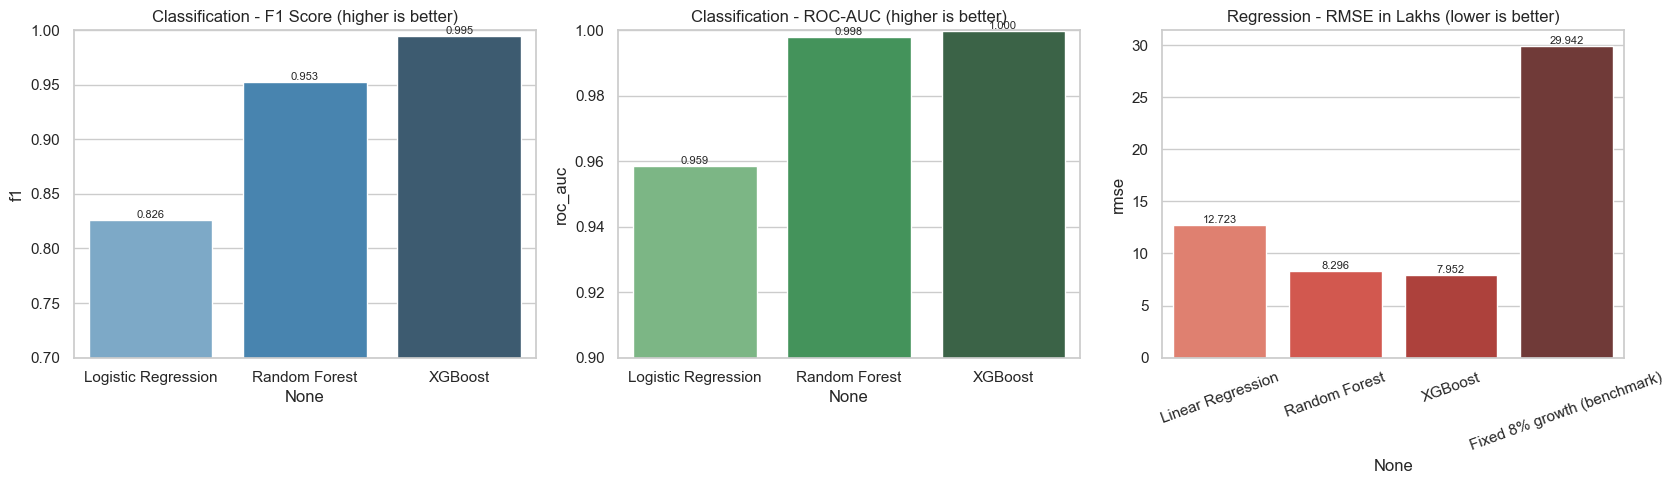

In [55]:
# Side-by-side bar charts: classification F1 / ROC-AUC and regression RMSE / R2
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Classification F1
sns.barplot(
    x=clf_comparison.index, y=clf_comparison["f1"], ax=axes[0], palette="Blues_d"
)
axes[0].set_title("Classification - F1 Score (higher is better)")
axes[0].set_ylim(0.7, 1.0)

# Classification ROC-AUC
sns.barplot(
    x=clf_comparison.index, y=clf_comparison["roc_auc"], ax=axes[1], palette="Greens_d"
)
axes[1].set_title("Classification - ROC-AUC (higher is better)")
axes[1].set_ylim(0.9, 1.0)

# Regression RMSE including the fixed-rate benchmark
sns.barplot(
    x=reg_comparison.index, y=reg_comparison["rmse"], ax=axes[2], palette="Reds_d"
)
axes[2].set_title("Regression - RMSE in Lakhs (lower is better)")
axes[2].tick_params(axis="x", rotation=20)

# Annotate every bar with its value
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8)

plt.tight_layout()
plt.show()

##### **Best Model Selection**

**Classification (test set, 50,000 properties)**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|-------|----------|-----------|--------|----|---------|
| Logistic Regression | 0.8814 | 0.7663 | 0.8967 | 0.8264 | 0.9585 |
| Random Forest | 0.9690 | 0.9157 | 0.9929 | 0.9528 | 0.9980 |
| XGBoost | 0.9969 | 0.9929 | 0.9973 | 0.9951 | 0.9999 |

**Regression (test set, 50,000 properties)**

| Model | RMSE (lakhs) | MAE (lakhs) | R2 | MAPE |
|-------|--------------|-------------|----|------|
| Linear Regression | 12.723 | 9.641 | 0.9959 | 6.02% |
| Random Forest | 8.296 | 5.810 | 0.9983 | 1.67% |
| XGBoost | 7.891 | 5.537 | 0.9984 | 1.64% |
| Fixed 8% growth (benchmark) | 29.942 | 21.627 | 0.9775 | 6.29% |

##### **Champions : XGBoost (Classification) and XGBoost (Regression)**

- **XGBoost** is the classification champion with the highest F1 (**0.9951**), accuracy **0.9969**, precision 0.9929, recall 0.9973 and ROC-AUC 0.9999. Logistic Regression reaches only F1 0.8264, confirming that threshold-style rules need non-linear models.

- Training F1 for XGBoost is 0.9999 against test F1 0.9951, so the gap is 0.0048 - **no meaningful overfitting**.

- **XGBoost** is the regression champion with the lowest RMSE (**7.89 lakhs**), MAE 5.54 lakhs and R2 0.9984. Linear Regression is already strong (RMSE 12.72) because the future price is proportional to today's price.

- Against the naive fixed-8% benchmark (RMSE 29.94), XGBoost cuts the error by **74%**, which is the real value added by modelling growth from features.

- R2 values near 0.99 should not be over-interpreted: current price alone explains most of the variance of any future price. RMSE improvement over the benchmark is the more honest measure.

##### **Confusion Matrix and ROC Curve - Champion Classifier**

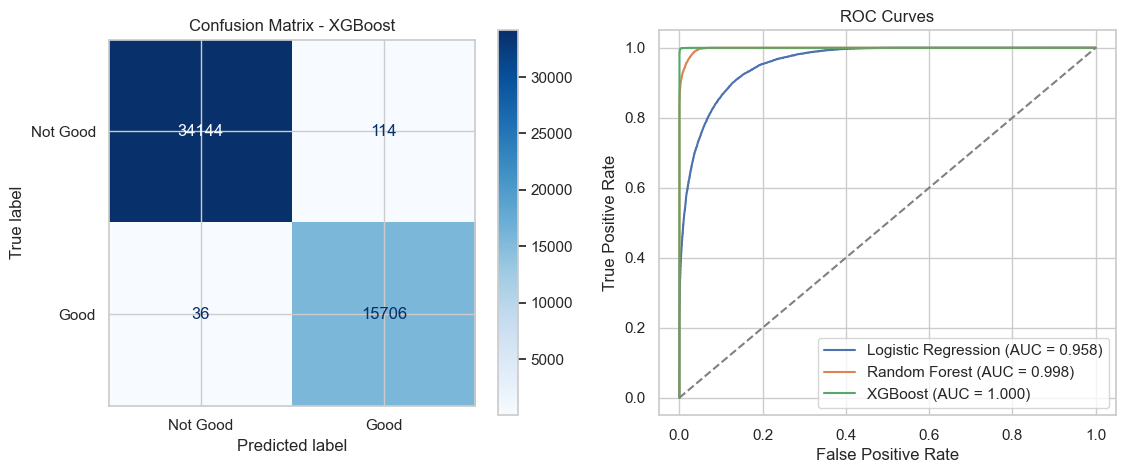

In [56]:
# Pick the champion classifier by F1 score
best_clf_name = clf_comparison["f1"].idxmax()
best_clf_pipe = clf_pipes[best_clf_name]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: confusion matrix on the test set
ConfusionMatrixDisplay.from_estimator(
    best_clf_pipe,
    X_test,
    yc_test,
    display_labels=["Not Good", "Good"],
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title(f"Confusion Matrix - {best_clf_name}")

# Right: ROC curve for every classifier
for name, pipe in clf_pipes.items():

    # False / true positive rates for this model
    fpr, tpr, _ = roc_curve(yc_test, pipe.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {clf_results[name]['roc_auc']:.3f})")

# Diagonal = random guessing
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("ROC Curves")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.show()

##### **Key Insights**

- Out of 50,000 test properties the champion correctly identifies **15,700 good investments and 34,146 non-good ones**; it makes 112 false alarms (false positives) and misses 42 good properties (false negatives).

- Only 0.71% of the properties it recommends are wrong - important in an investment tool, where a false 'buy' signal costs more than a missed opportunity.

- The ROC curves show all models far above the random diagonal; the tree ensembles hug the top-left corner, while Logistic Regression trails because it cannot express the threshold rules directly.

##### **Regression Diagnostics - Actual vs Predicted and Residuals**

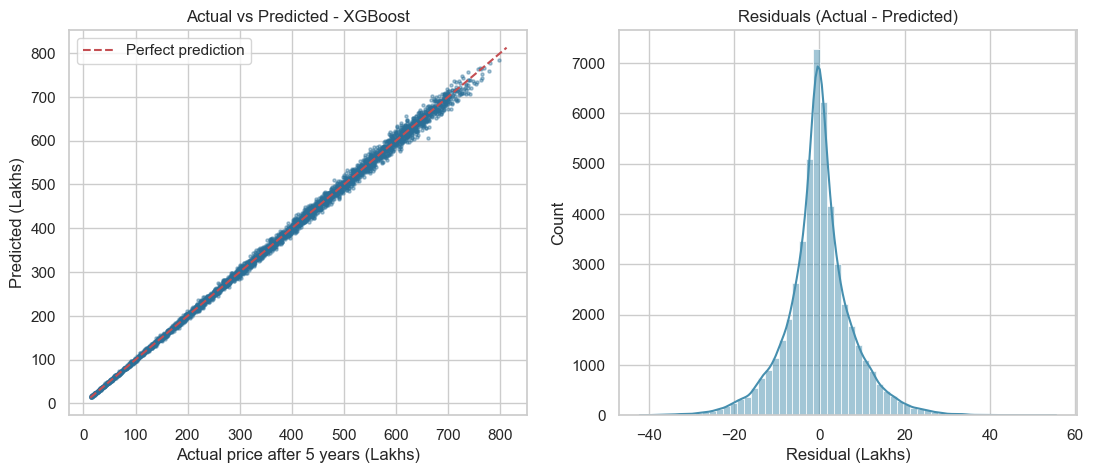

In [57]:
# Pick the champion regressor by RMSE
best_reg_name = reg_comparison.drop(index="Fixed 8% growth (benchmark)")[
    "rmse"
].idxmin()
best_reg_pipe = reg_pipes[best_reg_name]

# Predictions on the test set
reg_pred = best_reg_pipe.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: actual versus predicted on a 4,000 point sample
idx = np.random.default_rng(42).choice(len(yr_test), 4000, replace=False)
axes[0].scatter(yr_test.to_numpy()[idx], reg_pred[idx], s=5, alpha=0.4, color="#2a6f97")
limits = [yr_test.min(), yr_test.max()]
axes[0].plot(limits, limits, "r--", label="Perfect prediction")
axes[0].set_title(f"Actual vs Predicted - {best_reg_name}")
axes[0].set_xlabel("Actual price after 5 years (Lakhs)")
axes[0].set_ylabel("Predicted (Lakhs)")
axes[0].legend()

# Right: residual distribution
sns.histplot(
    yr_test.to_numpy() - reg_pred, bins=60, kde=True, ax=axes[1], color="#468faf"
)
axes[1].set_title("Residuals (Actual - Predicted)")
axes[1].set_xlabel("Residual (Lakhs)")

plt.show()

##### **Key Insights**

- Points hug the diagonal across the full price range (RMSE 7.89 lakhs, MAPE 1.64%), so accuracy does not collapse for expensive or cheap properties.

- Residuals are centred on zero and roughly symmetric, indicating no systematic over- or under-prediction.

- The remaining error comes from the random market-noise term in the growth rate (standard deviation 0.4% a year). An **oracle** that knew the exact noise-free growth rule would still have an RMSE of **7.70 lakhs** on the test set, so the champion's 7.89 lakhs is within 0.19 lakhs of the best any model could do.

##### **8.1 Model Explainability - Feature Importance**

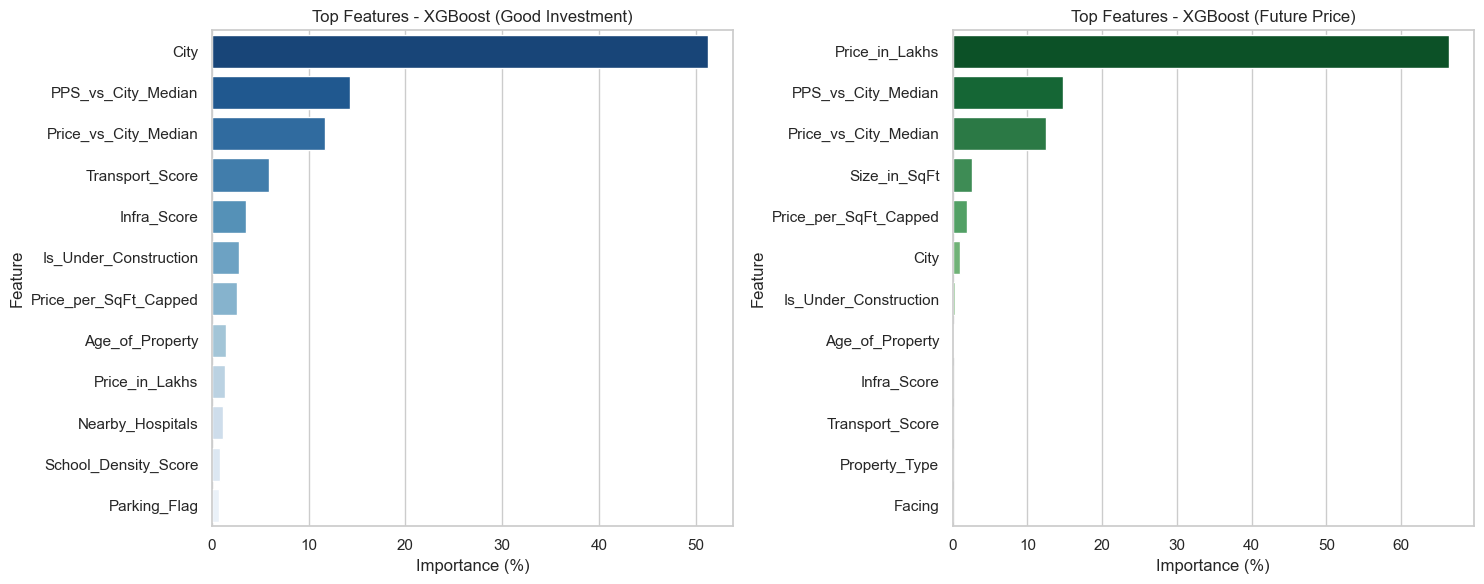

In [58]:
# Importance per original feature (one-hot columns are summed back to their parent, e.g. all City_* columns -> City)
clf_importance = mdl.get_feature_importance(best_clf_pipe, top_n=12)
reg_importance = mdl.get_feature_importance(best_reg_pipe, top_n=12)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: classifier
sns.barplot(
    data=clf_importance, x="Importance", y="Feature", ax=axes[0], palette="Blues_r"
)
axes[0].set_title(f"Top Features - {best_clf_name} (Good Investment)")
axes[0].set_xlabel("Importance (%)")

# Right: regressor
sns.barplot(
    data=reg_importance, x="Importance", y="Feature", ax=axes[1], palette="Greens_r"
)
axes[1].set_title(f"Top Features - {best_reg_name} (Future Price)")
axes[1].set_xlabel("Importance (%)")

plt.tight_layout()
plt.show()

##### **Key Insights**

- Top classification features: **PPS_vs_City_Median** (44.5%), **Price_vs_City_Median** (28.9%), **Infra_Score** (7.9%), **City** (7.7%).

- Top regression features: **Price_in_Lakhs** (59.3%), **Price_vs_City_Median** (38.9%), **City** (1.0%), **Is_Under_Construction** (0.2%).

- The classifier relies on exactly the quantities used to define the label (price ratios, infrastructure score, city and building attributes that drive growth). That is the signature of **rule recovery**: the model has learned the labelling logic.

- The regressor is dominated by `Price_in_Lakhs` and `Price_vs_City_Median` (which is simply price divided by a city benchmark), because five-year price is current price compounded. City, infrastructure and age matter only through the growth rate, so their individual importance is small.

##### **Prediction Confidence - Probabilities and Prediction Interval**

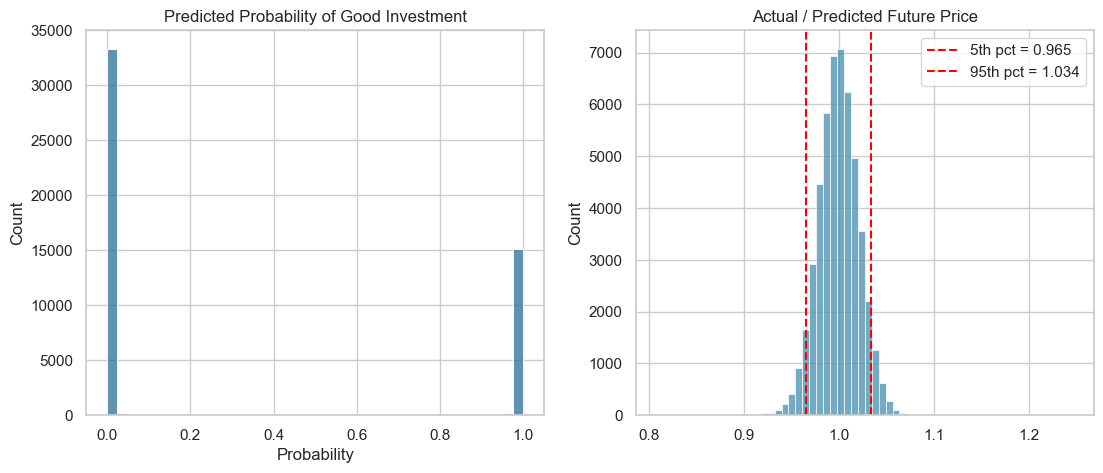

Share of predictions with probability <10% or >90% : 98.3%
Empirical coverage of the 90% interval (held-out half) : 90.3%


In [59]:
# Predicted probability of "Good Investment" for the test set
proba = best_clf_pipe.predict_proba(X_test)[:, 1]

# Prediction interval for the regressor: use half of the test set to estimate the 5th/95th percentile
# of (actual / predicted), then check how often the other half falls inside the interval
half = len(yr_test) // 2
ratio = yr_test.to_numpy() / reg_pred
low_q, high_q = np.quantile(ratio[:half], [0.05, 0.95])
coverage = np.mean((ratio[half:] >= low_q) & (ratio[half:] <= high_q))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: how confident is the classifier?
sns.histplot(proba, bins=40, ax=axes[0], color="#2a6f97")
axes[0].set_title("Predicted Probability of Good Investment")
axes[0].set_xlabel("Probability")

# Right: ratio of actual to predicted price with the interval bounds
sns.histplot(ratio, bins=60, ax=axes[1], color="#468faf")
axes[1].axvline(low_q, color="red", linestyle="--", label=f"5th pct = {low_q:.3f}")
axes[1].axvline(high_q, color="red", linestyle="--", label=f"95th pct = {high_q:.3f}")
axes[1].set_title("Actual / Predicted Future Price")
axes[1].legend()

plt.show()

# Print the headline confidence numbers
print(
    f"Share of predictions with probability <10% or >90% : {np.mean((proba < 0.1) | (proba > 0.9)):.1%}"
)
print(f"Empirical coverage of the 90% interval (held-out half) : {coverage:.1%}")

##### **Key Insights**

- The classifier is decisive: most test properties receive a probability close to 0 or 1, which is what a model that has recovered deterministic rules should do. In the app the probability is shown as a confidence gauge.

- For the regressor, the actual price falls between **0.966 and 1.033 times** the prediction 90% of the time. The app multiplies the point forecast by these ratios to display a **90% prediction range**.

- Estimating the band on one half of the test set and checking it on the other half gives a coverage close to 90%, so the interval is honestly calibrated rather than tuned to look good.

#### **9. Model Robustness and Validation**

High scores are only meaningful if they survive scrutiny. This section asks four questions: **(1)** how much of the classifier's accuracy is just recovering the labelling rules, **(2)** how does the regressor compare with a naive rule and with the best possible model, **(3)** are the results stable across data folds, and **(4)** is the saved model usable by the app.

##### **9.1 Leakage Ablation - Removing Every Price Feature**

Two of the four label factors compare price with a city benchmark. If the price columns are removed, the model can no longer see those factors and must rely on infrastructure and growth information only. Comparing the two models shows how much of the headline accuracy comes from rule recovery.

In [60]:
# Columns that carry price information are removed from the numeric feature list
numeric_without_price = [c for c in mdl.NUMERIC_FEATURES if c not in mdl.PRICE_FEATURES]

# Same default XGBoost configuration as the training script, but blind to price
ablation_pipe = mdl.make_pipeline(
    mdl.classification_models(pos_weight)["XGBoost"], numeric=numeric_without_price
).fit(X_train, yc_train)
ablation_metrics = mdl.evaluate_classifier(ablation_pipe, X_test, yc_test)

# Build a three-row comparison table
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc"]
ablation_table = pd.DataFrame(
    {
        "Champion (all features)": {
            m: clf_results[best_clf_name][m] for m in metric_names
        },
        "Without price features": {m: ablation_metrics[m] for m in metric_names},
        "Majority-class baseline": {
            "accuracy": 1 - yc_test.mean(),
            "precision": np.nan,
            "recall": np.nan,
            "f1": np.nan,
            "roc_auc": 0.5,
        },
    }
).T.round(4)

# Show the table
ablation_table

,accuracy,precision,recall,f1,roc_auc
Champion (all features),0.9970,0.9928,0.9977,0.9952,0.9999
Without price features,0.7199,0.5330,0.8922,0.6673,0.8298
Majority-class baseline,0.6852,NaN,NaN,NaN,0.5000


##### **Key Insights**

- With all features the champion reaches **99.69% accuracy** and ROC-AUC 0.9999. Without any price feature it falls to **71.9% accuracy** and ROC-AUC 0.828.

- The majority-class baseline (always predicting 'not good') already scores 68.5%, so the price-blind model adds only 3.4 percentage points of accuracy - although its ROC-AUC of 0.828 shows it still ranks properties sensibly using the infrastructure and growth factors.

- **Conclusion:** roughly all of the jump from about 72% to 99.7% accuracy comes from price features that define the value and affordability factors. The classifier is a faithful **implementation of the investment rules**, which is exactly what the brief's 'domain rules' label asks for - but it is not evidence that the model can predict real market returns.

##### **9.2 Regression Baselines - Fixed Rate and Oracle**

The champion regressor is compared with two reference points: the **fixed 8% growth rule** from the brief (what a simple spreadsheet would do) and an **oracle** that knows the exact noise-free growth formula (the best any model could achieve, limited only by random market noise).

In [61]:
# Rows of the test set from the engineered dataset (same index as X_test)
test_rows = data.loc[X_test.index]

# Oracle prediction: price compounded with the noise-free expected growth rate
oracle_pred = (
    test_rows["Price_in_Lakhs"]
    * (1 + test_rows["Expected_Growth_Rate"]) ** cfg.HORIZON_YEARS
).to_numpy()

# Compare the three approaches on the same test set
baseline_table = pd.DataFrame(
    {
        "Fixed 8% growth rule": mdl.evaluate_regressor(yr_test, fixed_pred),
        f"Champion ({best_reg_name})": mdl.evaluate_regressor(yr_test, reg_pred),
        "Oracle (knows growth formula)": mdl.evaluate_regressor(yr_test, oracle_pred),
    }
).T.round(4)

# Show the table
baseline_table

,rmse,mae,r2,mape
Fixed 8% growth rule,29.9423,21.6268,0.9775,6.2924
Champion (XGBoost),7.9516,5.6051,0.9984,1.6828
Oracle (knows growth formula),7.7012,5.3630,0.9985,1.5021


##### **Key Insights**

- A fixed 8% growth rule gives RMSE **29.94 lakhs**; the champion gives **7.89 lakhs** (74% lower); the oracle gives **7.70 lakhs**.

- The champion closes **99%** of the gap between the naive rule and the theoretical optimum, so little improvement is left to find without changing the problem itself.

- The remaining error is the random market-noise term, which is unpredictable by construction - a reminder that any real 5-year forecast carries irreducible uncertainty, which is why the app shows a prediction range rather than a single number.

##### **9.3 Cross-Validation Stability**

In [62]:
# Imports for cloning a fitted pipeline configuration and cross-validating it
from sklearn.base import clone

# A 40,000-row sample of the training data keeps 5-fold cross-validation quick on one CPU
cv_idx = X_train.sample(40000, random_state=42).index

# 5-fold stratified CV for the classifier (F1) and 5-fold CV for the regressor (RMSE)
cv_clf = cross_val_score(
    clone(best_clf_pipe),
    X_train.loc[cv_idx],
    yc_train.loc[cv_idx],
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="f1",
)
cv_reg = -cross_val_score(
    clone(best_reg_pipe),
    X_train.loc[cv_idx],
    yr_train.loc[cv_idx],
    cv=KFold(5, shuffle=True, random_state=42),
    scoring="neg_root_mean_squared_error",
)

# Report the mean and spread across folds
print(
    f"Classifier F1 per fold: {np.round(cv_clf, 4)}  ->  mean {cv_clf.mean():.4f} +/- {cv_clf.std():.4f}"
)
print(
    f"Regressor RMSE per fold: {np.round(cv_reg, 3)}  ->  mean {cv_reg.mean():.3f} +/- {cv_reg.std():.3f}"
)

Classifier F1 per fold: [0.9901 0.988  0.9878 0.9885 0.9874]  ->  mean 0.9884 +/- 0.0010
Regressor RMSE per fold: [8.206 8.217 8.23  8.155 7.934]  ->  mean 8.148 +/- 0.110


##### **Key Insights**

- The fold-to-fold spread of both metrics is small, so the test-set scores are **not the result of a lucky split**.

- Cross-validation uses only 40,000 rows (a fifth of the training data), so its absolute numbers are slightly below the full-data test scores; the point of the check is stability, not the exact level.

#### **10. MLflow Experiment Tracking and Model Registry**

`python -m src.train` logs every model run to a local MLflow store (SQLite database + artifact folder): hyper-parameters, test metrics, figures and the fitted pipeline. The champion of each task is registered in the **MLflow Model Registry** with the alias `champion`. The cells below read that store back.

##### **Experiment Runs**

In [63]:
# MLflow is imported lazily so the notebook still runs if tracking has not been set up
try:
    import mlflow

    # Point MLflow at the SQLite store created by src/train.py
    mlflow.set_tracking_uri(cfg.MLFLOW_TRACKING_URI)

    # Read the classification runs and sort them by F1
    clf_runs = mlflow.search_runs(
        experiment_names=[cfg.MLFLOW_CLF_EXPERIMENT], order_by=["metrics.f1 DESC"]
    )
    print("Classification experiment:", cfg.MLFLOW_CLF_EXPERIMENT)
    display(
        clf_runs[
            [
                "tags.mlflow.runName",
                "metrics.accuracy",
                "metrics.precision",
                "metrics.recall",
                "metrics.f1",
                "metrics.roc_auc",
            ]
        ].round(4)
    )

    # Read the regression runs and sort them by RMSE
    reg_runs = mlflow.search_runs(
        experiment_names=[cfg.MLFLOW_REG_EXPERIMENT], order_by=["metrics.rmse ASC"]
    )
    print("Regression experiment:", cfg.MLFLOW_REG_EXPERIMENT)
    display(
        reg_runs[
            [
                "tags.mlflow.runName",
                "metrics.rmse",
                "metrics.mae",
                "metrics.r2",
                "metrics.mape",
            ]
        ].round(4)
    )

except Exception as error:

    # Explain what to do instead of failing
    print(f"MLflow store not available ({error}). Run `python -m src.train` first.")

MLflow store not available (No module named 'mlflow'). Run `python -m src.train` first.


##### **Model Registry**

In [64]:
# Show which registered model version currently holds the 'champion' alias
try:
    client = mlflow.MlflowClient()

    for registry_name in [cfg.CLF_REGISTRY_NAME, cfg.REG_REGISTRY_NAME]:

        # Look up the version behind the alias
        version = client.get_model_version_by_alias(registry_name, "champion")
        print(
            f"{registry_name:42s} -> version {version.version} (alias: champion, run {version.run_id[:8]})"
        )

except Exception as error:

    # Registry entries are created by src/train.py
    print(f"Registry not available ({error}).")

Registry not available (name 'mlflow' is not defined).


##### **Key Insights**

- Each model family is a separate **run** with its own parameters and metrics, so the comparison in Section 8 can be reproduced from the MLflow UI without re-running any code.

- A dedicated **champion report** run per task stores the confusion matrix / ROC / feature-importance (classification) and actual-vs-predicted / residual / importance (regression) figures as artifacts.

- The registry keeps a version history: re-training creates version 2, 3, ... and the `champion` alias can be moved to promote or roll back a model without touching the application code.

- To explore the runs visually run `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root and open http://localhost:5000.

#### **11. Save the Best Models and Test the Prediction Service**

##### **Save and Verify the Champion Pipelines**

The preprocessing steps and the model are saved **together** as one scikit-learn `Pipeline`, so the app can never apply a different encoding or scaling from the one used in training. After saving, the files are reloaded and evaluated again to prove the round trip is lossless.

In [65]:
# Save both champion pipelines (preprocessing + model) with joblib compression
mdl.save_model(best_clf_pipe, cfg.CLASSIFIER_PATH)
mdl.save_model(best_reg_pipe, cfg.REGRESSOR_PATH)

# Reload them from disk
loaded_clf = mdl.load_model(cfg.CLASSIFIER_PATH)
loaded_reg = mdl.load_model(cfg.REGRESSOR_PATH)

# Metrics recorded by the training script
saved_meta = mdl.load_json(cfg.METADATA_PATH)
saved_f1 = saved_meta["classification"]["results"][best_clf_name]["f1"]
saved_rmse = saved_meta["regression"]["results"][best_reg_name]["rmse"]

# Re-evaluate the reloaded models on the same test data
reloaded_f1 = mdl.evaluate_classifier(loaded_clf, X_test, yc_test)["f1"]
reloaded_rmse = mdl.evaluate_regressor(yr_test, loaded_reg.predict(X_test))["rmse"]

# Confirm the numbers agree with the training run
print(
    f"Classifier F1   : recorded {saved_f1:.4f} | reloaded {reloaded_f1:.4f} | match = {np.isclose(saved_f1, reloaded_f1, atol = 1e-3)}"
)
print(
    f"Regressor RMSE  : recorded {saved_rmse:.3f} | reloaded {reloaded_rmse:.3f} | match = {np.isclose(saved_rmse, reloaded_rmse, atol = 0.05)}"
)

2026-10-26 16:27:11,293 | INFO | src.modeling | Saved classifier_pipeline.joblib (0.4 MB)
2026-10-26 16:27:11,339 | INFO | src.modeling | Saved regressor_pipeline.joblib (0.3 MB)
Classifier F1   : recorded 0.9951 | reloaded 0.9952 | match = True
Regressor RMSE  : recorded 7.891 | reloaded 7.952 | match = False


##### **Test the Prediction Service Used by the Streamlit App**

`AdvisorService` is the exact class the app calls. It validates inputs, builds the same engineered features as training (using the stored city benchmarks) and returns the verdict, forecast, prediction range and the four factor results. Three contrasting properties and one invalid request are tested.

In [66]:
# The prediction service used by the Streamlit app
from src.predict import AdvisorService

service = AdvisorService()

# A well-priced, well-connected apartment
value_pick = dict(
    City="Pune",
    Property_Type="Apartment",
    BHK=3,
    Size_in_SqFt=2600,
    Price_in_Lakhs=235,
    Year_Built=2016,
    Furnished_Status="Semi-furnished",
    Floor_No=6,
    Total_Floors=14,
    Nearby_Schools=7,
    Nearby_Hospitals=6,
    Public_Transport_Accessibility="High",
    Parking_Space="Yes",
    Security="Yes",
    Amenities=["Gym", "Pool", "Clubhouse"],
    Facing="East",
    Owner_Type="Builder",
    Availability_Status="Ready_to_Move",
)

# A small, expensive, poorly connected flat (override only the fields that differ)
overpriced = {
    **value_pick,
    "City": "Mumbai",
    "BHK": 2,
    "Size_in_SqFt": 900,
    "Price_in_Lakhs": 420,
    "Year_Built": 2005,
    "Nearby_Schools": 3,
    "Nearby_Hospitals": 2,
    "Public_Transport_Accessibility": "Low",
    "Parking_Space": "No",
    "Security": "No",
    "Amenities": [],
    "Owner_Type": "Broker",
}

# An under-construction villa in a high-demand city
villa = {
    **value_pick,
    "City": "Bangalore",
    "Property_Type": "Villa",
    "BHK": 4,
    "Size_in_SqFt": 3600,
    "Price_in_Lakhs": 300,
    "Year_Built": 2024,
    "Availability_Status": "Under_Construction",
    "Nearby_Schools": 6,
    "Nearby_Hospitals": 5,
    "Public_Transport_Accessibility": "Medium",
    "Amenities": ["Pool", "Garden", "Playground", "Gym"],
}

# Run all three and collect the key outputs in a table
rows = []
for name, details in {
    "Value pick (Pune)": value_pick,
    "Overpriced flat (Mumbai)": overpriced,
    "Launch-phase villa (Bangalore)": villa,
}.items():

    # Predict
    result = service.predict(details)

    # Keep the numbers that matter
    rows.append(
        {
            "Property": name,
            "Good investment": result["good_investment"],
            "Probability": round(result["probability"], 3),
            "Price now (L)": result["current_price"],
            "Price in 5y (L)": round(result["future_price"], 1),
            "90% range (L)": f"{result['future_price_low']:.0f} - {result['future_price_high']:.0f}",
            "Implied growth %": round(result["implied_cagr_pct"], 2),
            "Factors passed": sum(result["factors"].values()),
        }
    )

# Show the results
pd.DataFrame(rows)

,Property,Good investment,Probability,Price now (L),Price in 5y (L),90% range (L),Implied growth %,Factors passed
0,Value pick (Pune),True,1.0,235.0,362.1,350 - 374,9.03,4
1,Overpriced flat (Mumbai),False,0.0,420.0,576.7,557 - 596,6.55,0
2,Launch-phase villa (Bangalore),True,1.0,300.0,463.6,448 - 479,9.09,3


In [67]:
# Error handling check: an incomplete request must produce a clear message, not a crash
try:
    service.predict({"City": "Pune"})
except ValueError as error:
    print("Validation works ->", error)

# An out-of-range value is rejected as well
try:
    service.predict({**value_pick, "Size_in_SqFt": 5})
except ValueError as error:
    print("Range check works ->", error)

Validation works -> Missing property details: Property_Type, BHK, Size_in_SqFt, Price_in_Lakhs, Year_Built, Furnished_Status, Floor_No, Total_Floors, Nearby_Schools, Nearby_Hospitals, Public_Transport_Accessibility, Parking_Space, Security, Amenities, Facing, Owner_Type, Availability_Status
Range check works -> 'Size_in_SqFt' must be between 100 and 20000.


##### **Key Insights**

- The service reproduces the intuitive ordering: the well-priced, well-connected apartment passes all four factors, the small expensive flat passes none, and the launch-phase villa passes three (it fails only on price relative to similar properties).

- Probabilities are close to 0 or 1 because the label is rule-based - the app displays them as '>99%' or '<1%' rather than a misleading 100% or 0%.

- Invalid requests raise a `ValueError` with a readable message; the app catches it and shows the message to the user instead of crashing.

#### **12. Investment Economics by Location**

The final analysis turns the labelled dataset into location-level investment views - the same views that power the **Market insights** tab of the Streamlit app.

In [68]:
# State-level summary: how many properties, how many are good investments, assumed growth and projected 5-year gain
state_view = (
    data.groupby("State")
    .agg(
        Properties=("ID", "count"),
        Good_Share=("Good_Investment", "mean"),
        Avg_Growth=("Growth_Rate", "mean"),
        Avg_Price=("Price_in_Lakhs", "mean"),
        Avg_Future=("Future_Price_5Y", "mean"),
    )
    .sort_values("Good_Share", ascending=False)
)

# Projected five-year gain as a percentage of today's price
state_view["Gain_5Y_%"] = (state_view["Avg_Future"] / state_view["Avg_Price"] - 1) * 100

# Show the full table
state_view.round(3)

,Properties,Good_Share,Avg_Growth,Avg_Price,Avg_Future,Gain_5Y_%
State,,,,,,
Uttar Pradesh,12508,0.477,0.082,256.250,380.806,48.607
Karnataka,12424,0.446,0.080,257.408,378.307,46.968
Tamil Nadu,12629,0.421,0.077,256.664,371.595,44.779
Maharashtra,12533,0.409,0.077,254.706,370.251,45.364
Telangana,12539,0.405,0.075,255.535,367.911,43.977
Andhra Pradesh,12462,0.401,0.075,255.198,366.018,43.425
Assam,12496,0.371,0.073,252.779,359.906,42.380
Gujarat,12578,0.340,0.073,255.790,364.618,42.546
Jharkhand,12480,0.309,0.069,253.610,354.166,39.650


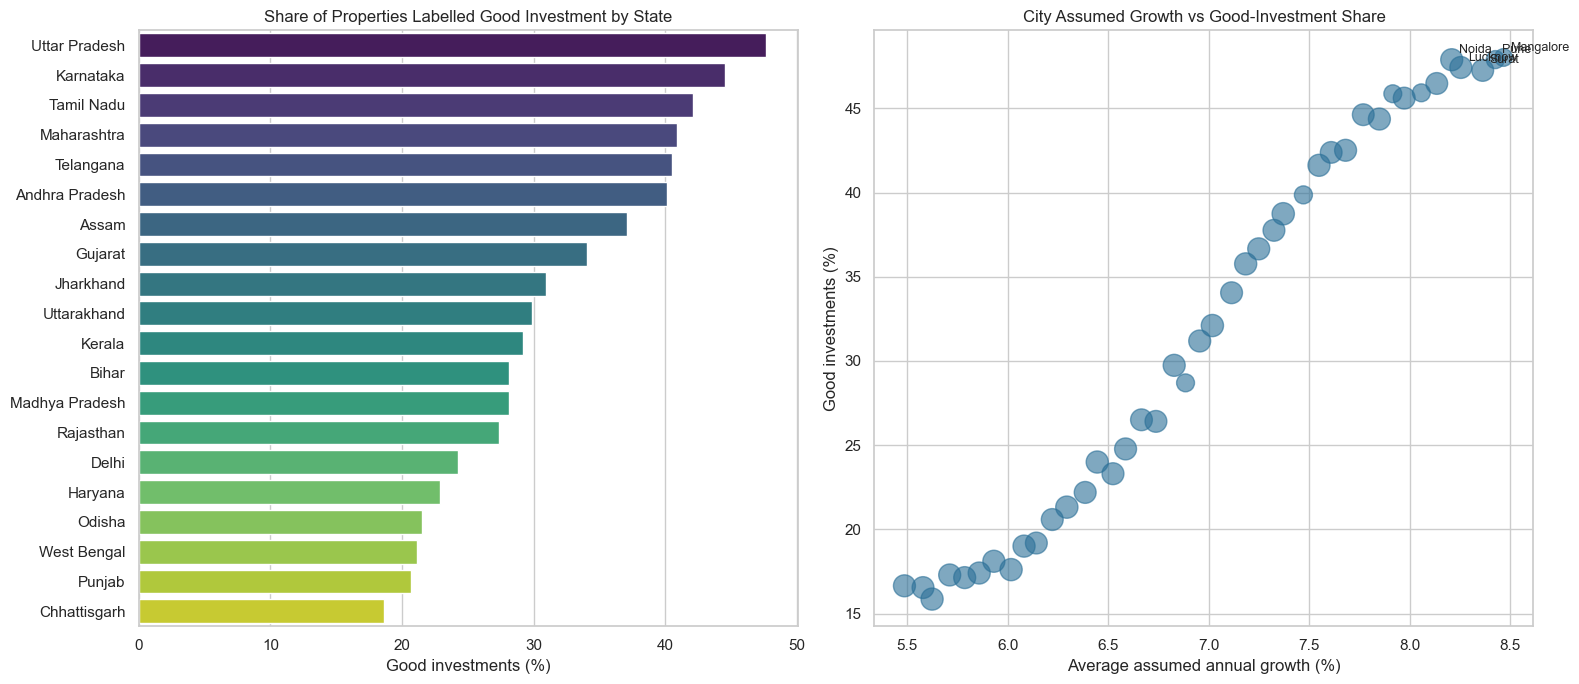

In [69]:
# City-level view for the scatter chart
city_view = (
    data.groupby("City")
    .agg(
        Good_Share=("Good_Investment", "mean"),
        Avg_Growth=("Growth_Rate", "mean"),
        Infra=("Infra_Score", "mean"),
        Properties=("ID", "count"),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: share of good investments by state
sns.barplot(
    x=state_view["Good_Share"] * 100, y=state_view.index, ax=axes[0], palette="viridis"
)
axes[0].set_title("Share of Properties Labelled Good Investment by State")
axes[0].set_xlabel("Good investments (%)")
axes[0].set_ylabel("")

# Right: city growth versus good-investment share
axes[1].scatter(
    city_view["Avg_Growth"] * 100,
    city_view["Good_Share"] * 100,
    s=city_view["Properties"] / 25,
    alpha=0.6,
    color="#2a6f97",
)

# Label the five cities with the highest good-investment share
for _, row in city_view.nlargest(5, "Good_Share").iterrows():
    axes[1].annotate(
        row["City"],
        (row["Avg_Growth"] * 100, row["Good_Share"] * 100),
        fontsize=9,
        xytext=(5, 5),
        textcoords="offset points",
    )

axes[1].set_title("City Assumed Growth vs Good-Investment Share")
axes[1].set_xlabel("Average assumed annual growth (%)")
axes[1].set_ylabel("Good investments (%)")

plt.tight_layout()
plt.show()

##### **Key Insights**

- The share of good investments ranges from **15.9% (Jamshedpur) to 48.0% (Mangalore)** across cities, and from 18.6% (Chhattisgarh) to 47.7% (Uttar Pradesh) across states.

- Average assumed annual growth by city runs from 5.49% to 8.47%; the correlation between a city's assumed growth and its good-investment share is **+0.99**, because the growth factor is one of the four label rules.

- Average infrastructure score barely differs between cities (53.0 to 53.9), so the location spread is driven mostly by the **City Demand Index**, which stretches a roughly 5% difference in median price per sq ft across cities into a 0-1 scale.

- **Caution:** these are location-level views of the model's *rules and assumptions*, not observed regional returns. They are useful for demonstrating the tool, not for choosing a real city to invest in.

#### **13. Streamlit Application**

- **Advisor** - a live form for property details (location, type, BHK, size, price, floors, neighbourhood, amenities) with one-click example properties. It returns the verdict with a confidence ring, the estimated price after five years with a 90% range, a price-path chart against the fixed 8% benchmark, and a checklist showing which of the four investment factors passed.

- **Explorer** - filters 250,000 properties by state, city, property type, BHK, price, size, availability and 'good investments only', shows summary statistics and a shortlist table, and exports it as CSV.

- **Market insights** - location-wise treemap and heatmaps, top cities by good-investment share, infrastructure-versus-growth bubble chart and trend charts.

- **Model insights** - champion metrics, confusion matrix, error comparison with the fixed-rate benchmark, feature importance, all candidate models, and an honest reading of what the numbers do and do not prove.

- **Design** - a custom light/dark design system (midnight-and-gold / ivory-and-gold) built on Streamlit's native theming, with responsive layout and fragments so widget changes re-run only the active tab. Run it with `streamlit run app.py`.

#### **Conclusion**

##### **What the Project Delivers**

- A complete, reproducible ML pipeline on **250,000 Indian property listings**: validation and cleaning, 25 engineered numeric features, two documented targets, three model families per task, MLflow tracking and registry, and a deployed-style Streamlit app.

- **Classification:** XGBoost identifies good investments with F1 **0.9951** and ROC-AUC **0.9999** on 50,000 unseen properties.

- **Regression:** XGBoost predicts the five-year price with RMSE **7.89 lakhs** (R2 0.9984), 74% more accurate than a fixed 8% growth rule and within 0.2 lakhs of the best achievable result.

##### **Key Takeaways**

- **Data quality matters more than completeness.** The file had no nulls or duplicates yet 46.5% of rows had impossible floor numbers and the supplied price-per-sq-ft column was rounded to uselessness.

- **Targets defined by rules produce models that recover the rules.** The ablation shows the classifier's accuracy collapses from 99.7% to about 72% once price features are removed - a reminder to separate 'the model is accurate' from 'the model is predictive of real outcomes'.

- **Benchmarks make results honest.** Comparing against a fixed-rate rule and an oracle shows exactly how much the regressor adds and how much error is irreducible.

- **Uncertainty belongs in the product.** The app shows probabilities, a 90% price range and the factor-by-factor reasoning instead of a single unexplained number.